# Đề 3 — Dự đoán độ trễ mạng từ kích thước gói tin và tải mạng
**Môn:** Phương pháp thống kê dữ liệu (Chương 6 – Hồi quy tuyến tính, Chương 7 – Thống kê phi tham số)
**Công cụ:** Python 3 (`numpy`, `pandas`, `scipy`, `statsmodels`, `matplotlib`) — chạy được từ đầu đến cuối bằng *Run All*.

---
## Câu chuyện của bài (đọc 1 phút là nắm được)

> Nhóm vận hành mạng muốn **dự đoán độ trễ (ms)**. Có hai "nghi phạm": **kích thước gói tin** ($x_1$, byte) và **tải mạng** ($x_2$, %). Câu hỏi: *mỗi yếu tố đóng góp bao nhiêu? Chỉ dùng một yếu tố thì sai ở đâu? Dự đoán được đến mức nào và đáng tin ở đâu?*

**Sơ đồ phân tích — mỗi mục trả lời đúng một yêu cầu của đề:**

| Mục | Nội dung | Yêu cầu đề |
|---|---|---|
| 1 | Thiết kế thí nghiệm 5×3 lặp 4 lần & sinh dữ liệu | YC 1 |
| 2 | Khám phá dữ liệu (EDA) | bổ trợ |
| 3 | Hồi quy đơn (chỉ $x_1$) | YC 2 |
| 4 | Hồi quy bội ($x_1,x_2$) + ý nghĩa từng hệ số | YC 3, 4 |
| 5 | Kiểm định hệ số, $R^2$ hiệu chỉnh, so sánh phần dư | YC 5 |
| 6 | Kiểm tra giả định + kiểm chứng phi tham số (Chương 7) | củng cố độ tin cậy |
| 7 | Dự đoán tại $x_1=1000$, $x_2=60\%$ | YC 6 |
| 8 | Yếu tố thực tế chưa xét & giới hạn áp dụng | YC 7 |
| 9 | Biến cần thu thập (kết luận bắt buộc) | Kết luận |
| 10 | Mô phỏng Monte Carlo: *đánh giá chính phương pháp* | điểm nhấn |
| 11 | Bảng tổng hợp đáp án | tổng kết |


### 🔑 Kết quả chính (số liệu lấy từ lần chạy dưới đây, `SEED = 20261114`)
1. **Cả hai yếu tố đều quan trọng:** +100 byte ⇒ **+0,55 ms**; +10 điểm % tải ⇒ **+0,93 ms** (mỗi hệ số tính khi giữ biến kia cố định); cả hai có $p<0{,}0001$.
2. **Bỏ sót tải mạng làm mất một nửa sức mạnh:** $R^2_{hc}$ từ **0,343 → 0,684**; sai số dự đoán điển hình từ 3,19 → 2,21 ms. Phần dư của mô hình đơn *tách thành 3 tầng theo tải* (Kruskal–Wallis $p<0{,}0001$), mô hình bội thì hết ($p=0{,}91$).
3. **Phân rã biến thiên:** kích thước gói giải thích ≈ **35%**, tải mạng ≈ **34%**, nhiễu ≈ **31%**. Đi hết dải khảo sát: kích thước làm trễ tăng ≈ **6,6 ms**, tải ≈ **5,6 ms** — gần ngang nhau.
4. **Dự đoán (1000 byte, 60%):** **15,9 ms**; CI 95% cho trung bình **[15,2; 16,5]**, PI 95% cho một gói **[11,4; 20,3]**.
5. **Điểm nhấn mô phỏng:** thiết kế cân bằng giúp hệ số $\hat\beta_1$ của hồi quy đơn *trùng khít* hồi quy bội; nhưng với dữ liệu quan sát (tải và kích thước đi cùng nhau) mô hình đơn cho **0,010 — gấp đôi giá trị thật 0,005**, CI 95% gần như không bao giờ chứa giá trị thật (Mục 10).

**Quy ước làm việc (theo yêu cầu chung của đề):** mức ý nghĩa $\alpha=5\%$, tin cậy 95%; dữ liệu là **mô phỏng** (không trình bày như số đo thực); lưu seed, dữ liệu gốc, mã lệnh; **khi phân tích từng mẫu chỉ ước lượng từ mẫu — các tham số thật ($5; 0{,}005; 0{,}1; 2$) chỉ xuất hiện ở Mục 10 để *chấm điểm phương pháp*.**

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.multitest import multipletests
from scipy import stats
from IPython.display import display, Markdown

# ---- Cấu hình chung -------------------------------------------------
SEED  = 20261114           # hạt giống ngẫu nhiên: ghi rõ để tái lập
ALPHA = 0.05               # mức ý nghĩa 5%  -> tin cậy 95%
os.makedirs("figs", exist_ok=True)

C1, C2, C3, GREY, INK = "#2B6CB0", "#DD6B20", "#2F855A", "#718096", "#1A202C"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.labelsize": 10, "legend.frameon": False, "font.size": 10,
})
def savefig(name):
    plt.savefig(f"figs/{name}.png", bbox_inches="tight"); plt.show()

def fmt_p(p): return "<0.0001" if p < 1e-4 else f"{p:.4f}"
def coef_table(m):
    ci = m.conf_int(ALPHA)
    out = pd.DataFrame({"Hệ số": m.params, "Sai số chuẩn": m.bse, "t": m.tvalues,
                        "p-value": [fmt_p(p) for p in m.pvalues],
                        "CI 95% dưới": ci[0], "CI 95% trên": ci[1]})
    return out.round(5)
print("numpy", np.__version__, "| statsmodels", sm.__version__, "| seed =", SEED)

numpy 2.5.3 | statsmodels 0.15.0 | seed = 20261114


---
# 1. Thiết kế thí nghiệm và sinh dữ liệu  *(Yêu cầu 1)*

### 1.1 Thiết kế: giai thừa đầy đủ 5 × 3 có lặp
- $x_1\in\{200,500,800,1100,1400\}$ byte (5 mức), $x_2\in\{20,50,80\}\%$ (3 mức) → **15 tổ hợp**.
- Mỗi tổ hợp lấy **4 quan sát lặp** → $15\times 4=60$ quan sát.

### 1.2 Vì sao thiết kế này tốt? (lợi ích — điểm cần nói với giảng viên)
| # | Lợi ích | Giải thích ngắn |
|---|---|---|
| 1 | **Cân bằng & trực giao** | Mọi mức $x_1$ gặp đủ cả 3 mức $x_2$ với số lần bằng nhau ⇒ $\text{corr}(x_1,x_2)=0$ ⇒ không đa cộng tuyến, hệ số ước lượng **không bị "lẫn" vào nhau**. |
| 2 | **Phủ toàn dải** | 5 mức $x_1$ và 3 mức $x_2$ trải rộng ⇒ ước lượng độ dốc có sai số chuẩn nhỏ nhất cho cùng số quan sát. |
| 3 | **Có lặp** | 4 lần lặp/tổ hợp cho ta ước lượng **sai số thuần túy** (pure error) ⇒ kiểm định được *mô hình có thẳng thật không* (lack-of-fit) — Mục 6. |
| 4 | **Phát hiện tương tác** | Có đủ tổ hợp chéo nên kiểm tra được "tác động của kích thước có đổi theo tải không". |
| 5 | **Ngẫu hóa thứ tự đo** | Xáo trộn thứ tự chạy để các yếu tố ẩn theo thời gian không gây thiên lệch hệ thống. |

In [2]:
x1_levels = [200, 500, 800, 1100, 1400]      # byte
x2_levels = [20, 50, 80]                      # %
N_REP = 4

# Bảng thiết kế: 15 tổ hợp
combos = pd.DataFrame([(a, b) for a in x1_levels for b in x2_levels], columns=["x1 (byte)", "x2 (%)"])
combos.insert(0, "Tổ hợp", range(1, len(combos) + 1))
combos["Số quan sát"] = N_REP
combos["Lũy kế"] = combos["Số quan sát"].cumsum()
display(combos)

# Ma trận thiết kế dạng bảng chéo
display(pd.crosstab(pd.Series([a for a in x1_levels for _ in range(N_REP*len(x2_levels))], name="x1 (byte)"),
                    pd.Series([b for _ in x1_levels for b in x2_levels for _ in range(N_REP)], name="x2 (%)")))

,Tổ hợp,x1 (byte),x2 (%),Số quan sát,Lũy kế
0,1,200,20,4,4
1,2,200,50,4,8
2,3,200,80,4,12
3,4,500,20,4,16
4,5,500,50,4,20
5,6,500,80,4,24
6,7,800,20,4,28
7,8,800,50,4,32
8,9,800,80,4,36
9,10,1100,20,4,40


x2 (%),20,50,80
x1 (byte),,,
200,4,4,4
500,4,4,4
800,4,4,4
1100,4,4,4
1400,4,4,4


In [3]:
# Kiểm tra tính chất của thiết kế
design = combos.rename(columns={"x1 (byte)": "x1", "x2 (%)": "x2"})[["x1", "x2"]]
design = design.loc[design.index.repeat(N_REP)].reset_index(drop=True)
design["rep"] = design.groupby(["x1", "x2"]).cumcount() + 1
Xd = sm.add_constant(design[["x1", "x2"]].astype(float))

print(f"Số quan sát n = {len(design)}")
print(f"Tương quan Pearson giữa x1 và x2 = {design['x1'].corr(design['x2']):.6f}   (=0: trực giao)")
print("VIF (hệ số phóng đại phương sai):",
      {c: round(variance_inflation_factor(Xd.values, i), 3) for i, c in enumerate(Xd.columns) if c != "const"},
      "  (=1: không đa cộng tuyến)")

Số quan sát n = 60
Tương quan Pearson giữa x1 và x2 = 0.000000   (=0: trực giao)
VIF (hệ số phóng đại phương sai): {'x1': np.float64(1.0), 'x2': np.float64(1.0)}   (=1: không đa cộng tuyến)


### 1.3 Sinh dữ liệu
Mô hình sinh: $Y = 5 + 0{,}005\,x_1 + 0{,}1\,x_2 + \varepsilon,\ \varepsilon\sim N(0;2^2)$ (đơn vị ms), các $\varepsilon$ **độc lập**.
Các tham số này **chỉ dùng để tạo dữ liệu**; sau ô này ta xóa chúng khỏi dữ liệu phân tích và chỉ làm việc với cột `y` quan sát được.

In [4]:
rng = np.random.default_rng(SEED)
TRUE = {"b0": 5.0, "b1": 0.005, "b2": 0.1, "sigma": 2.0}   # CHỈ dùng ở Mục 10 để đánh giá phương pháp

eps = rng.normal(0, TRUE["sigma"], size=len(design))                 # N(0; 2^2), độc lập
y   = TRUE["b0"] + TRUE["b1"]*design["x1"] + TRUE["b2"]*design["x2"] + eps

df = design.copy()
df["y"]   = y.round(3)                                  # độ trễ (ms)
df["run"] = rng.permutation(len(df)) + 1                # ngẫu hóa thứ tự đo
df = df.sort_values("run").reset_index(drop=True)[["run", "x1", "x2", "rep", "y"]]
df.to_csv("data_de3_latency.csv", index=False)          # lưu dữ liệu gốc để tái lập

n = len(df)
display(df.head(8))
print(f"\nĐã lưu 'data_de3_latency.csv' ({n} dòng). Từ đây trở đi chỉ dùng cột x1, x2, y của df.")

,run,x1,x2,rep,y
0,1,200,50,4,11.152
1,2,1400,20,2,14.473
2,3,1100,20,4,14.401
3,4,800,80,1,17.291
4,5,1400,50,2,17.434
5,6,1100,50,4,22.185
6,7,1400,50,4,16.805
7,8,1400,20,4,17.907



Đã lưu 'data_de3_latency.csv' (60 dòng). Từ đây trở đi chỉ dùng cột x1, x2, y của df.


### 1.4 Kiểm tra nhanh dữ liệu vừa sinh (QA bộ sinh)
Trước khi phân tích, ta "nhìn" dữ liệu một lượt như người làm thật: giá trị nhỏ nhất/lớn nhất, các phân vị, độ lệch, hình dạng phân phối, và xem **bộ sinh nhiễu có đúng $N(0;2^2)$ như đề yêu cầu không**. Phần này chỉ kiểm tra *bộ sinh dữ liệu*; từ Mục 2 trở đi phân tích vẫn chỉ dùng $x_1,x_2,y$.

In [5]:
def five(v):
    q = np.percentile(v, [0, 25, 50, 75, 100])
    return pd.Series({"n": len(v), "Trung bình": np.mean(v), "Độ lệch chuẩn": np.std(v, ddof=1), "Min": q[0], "Q1 (25%)": q[1],
                      "Trung vị": q[2], "Q3 (75%)": q[3], "Max": q[4], "IQR": q[3] - q[1],
                      "Độ lệch (skew)": stats.skew(v), "Độ nhọn (kurt)": stats.kurtosis(v)})
qa = pd.concat({"Độ trễ y (ms)": five(df["y"].to_numpy()), "Nhiễu ε đã sinh (ms)": five(eps)}, axis=1)
display(qa.round(3))
sw_e = stats.shapiro(eps)
print(f"Kiểm tra bộ sinh: ε có TB = {eps.mean():.3f} (kỳ vọng 0), SD = {eps.std(ddof=1):.3f} (kỳ vọng 2); "
      f"Shapiro–Wilk p = {fmt_p(sw_e.pvalue)} → {'phù hợp phân phối chuẩn' if sw_e.pvalue>ALPHA else 'lệch chuẩn'}")
print("Số quan sát mỗi tổ hợp x1×x2: min =", df.groupby(['x1','x2']).size().min(), ", max =", df.groupby(['x1','x2']).size().max(), "→ cân bằng")

,Độ trễ y (ms),Nhiễu ε đã sinh (ms)
n,60.000,60.000
Trung bình,13.840,-0.160
Độ lệch chuẩn,3.931,2.187
Min,5.718,-5.780
Q1 (25%),11.149,-1.372
Trung vị,14.038,-0.059
Q3 (75%),16.335,1.035
Max,22.185,6.685
IQR,5.186,2.407
Độ lệch (skew),-0.026,-0.003


Kiểm tra bộ sinh: ε có TB = -0.160 (kỳ vọng 0), SD = 2.187 (kỳ vọng 2); Shapiro–Wilk p = 0.1757 → phù hợp phân phối chuẩn
Số quan sát mỗi tổ hợp x1×x2: min = 4 , max = 4 → cân bằng


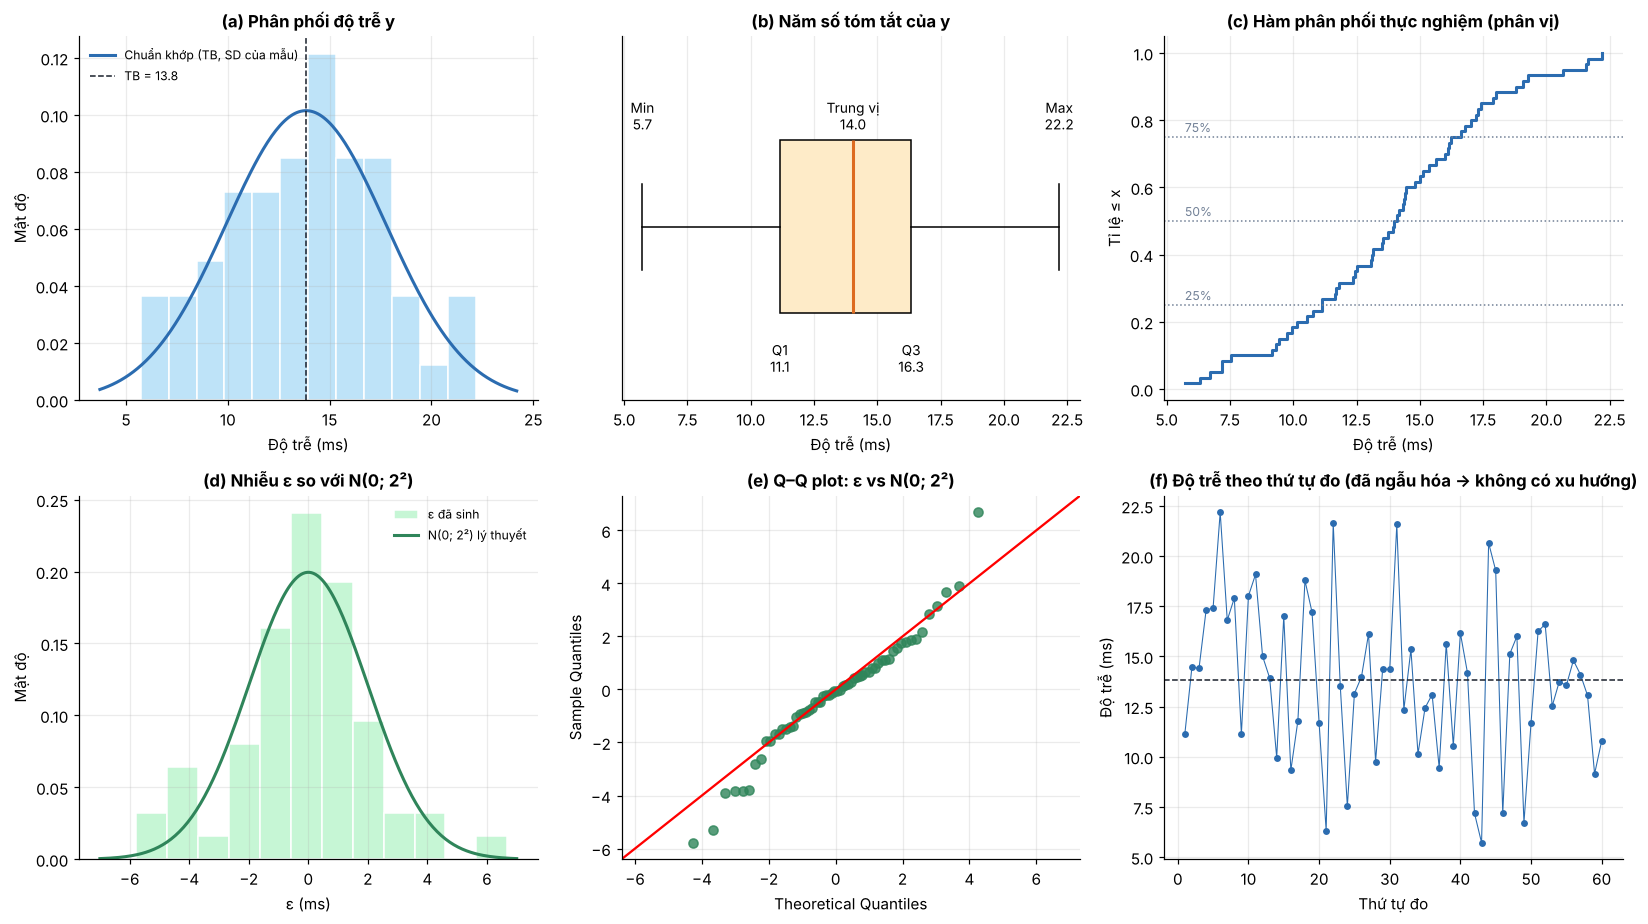

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))

# (a) Histogram của y + đường chuẩn khớp
ax[0, 0].hist(df["y"], bins=12, density=True, color="#BEE3F8", edgecolor="white")
xx = np.linspace(df["y"].min() - 2, df["y"].max() + 2, 200)
ax[0, 0].plot(xx, stats.norm.pdf(xx, df["y"].mean(), df["y"].std()), color=C1, lw=2, label="Chuẩn khớp (TB, SD của mẫu)")
ax[0, 0].axvline(df["y"].mean(), color=INK, ls="--", lw=1, label=f"TB = {df['y'].mean():.1f}")
ax[0, 0].set(title="(a) Phân phối độ trễ y", xlabel="Độ trễ (ms)", ylabel="Mật độ"); ax[0, 0].legend(fontsize=8)

# (b) Boxplot ngang có ghi min, Q1, trung vị, Q3, max
q = np.percentile(df["y"], [0, 25, 50, 75, 100])
ax[0, 1].boxplot(df["y"], vert=False, widths=.5, patch_artist=True, boxprops=dict(facecolor="#FEEBC8"),
                 medianprops=dict(color=C2, lw=2), whis=(0, 100))
for val, lab, dy in zip(q, ["Min", "Q1", "Trung vị", "Q3", "Max"], [.32, -.38, .32, -.38, .32]):
    ax[0, 1].annotate(f"{lab}\n{val:.1f}", (val, 1), (val, 1 + dy), ha="center", va="center", fontsize=9)
ax[0, 1].set(title="(b) Năm số tóm tắt của y", xlabel="Độ trễ (ms)", yticks=[], ylim=(.5, 1.55)); ax[0, 1].grid(axis="y", visible=False)

# (c) ECDF của y
ys = np.sort(df["y"]); ax[0, 2].step(ys, np.arange(1, n + 1) / n, where="post", color=C1, lw=2)
for pr in (.25, .5, .75):
    ax[0, 2].axhline(pr, color=GREY, ls=":", lw=1); ax[0, 2].text(ys[0], pr + .015, f"{int(pr*100)}%", color=GREY, fontsize=8)
ax[0, 2].set(title="(c) Hàm phân phối thực nghiệm (phân vị)", xlabel="Độ trễ (ms)", ylabel="Tỉ lệ ≤ x")

# (d) Histogram của ε + N(0; 2²)
ax[1, 0].hist(eps, bins=12, density=True, color="#C6F6D5", edgecolor="white", label="ε đã sinh")
xe = np.linspace(-7, 7, 200); ax[1, 0].plot(xe, stats.norm.pdf(xe, 0, TRUE["sigma"]), color=C3, lw=2, label="N(0; 2²) lý thuyết")
ax[1, 0].set(title="(d) Nhiễu ε so với N(0; 2²)", xlabel="ε (ms)", ylabel="Mật độ"); ax[1, 0].legend(fontsize=8)

# (e) Q–Q của ε
sm.qqplot(eps, stats.norm, loc=0, scale=TRUE["sigma"], line="45", ax=ax[1, 1], markerfacecolor=C3, markeredgecolor=C3, alpha=.8)
ax[1, 1].set_title("(e) Q–Q plot: ε vs N(0; 2²)")

# (f) y theo thứ tự đo (kiểm tra ngẫu hóa)
ax[1, 2].plot(df["run"], df["y"], marker="o", ms=3.5, lw=.7, color=C1)
ax[1, 2].axhline(df["y"].mean(), color=INK, ls="--", lw=1)
ax[1, 2].set(title="(f) Độ trễ theo thứ tự đo (đã ngẫu hóa → không có xu hướng)", xlabel="Thứ tự đo", ylabel="Độ trễ (ms)")
plt.tight_layout(); savefig("fig00_data_check")

**Đọc kết quả:** (a),(b),(c) cho thấy độ trễ trải khoảng từ min đến max đã ghi, phân phối khá cân đối quanh trung bình (độ lệch gần 0); (d),(e) xác nhận nhiễu sinh ra **đúng dạng $N(0;2^2)$** — điểm trên Q–Q bám sát đường 45°; (f) thứ tự đo đã ngẫu hóa nên không có xu hướng theo thời gian. Dữ liệu vậy là **đạt yêu cầu** để bắt đầu phân tích.

---
# 2. Khám phá dữ liệu (EDA)

**Mục đích:** nhìn dữ liệu trước khi mô hình hóa — xu hướng có tuyến tính không? Có điểm lạ không? Độ phân tán có đều không?

In [7]:
print("Thống kê mô tả của độ trễ Y (ms):")
display(df["y"].describe().round(3).to_frame("y"))

print("Trung bình / độ lệch chuẩn của Y theo từng tổ hợp (x1 × x2):")
cell = df.pivot_table(index="x1", columns="x2", values="y", aggfunc=["mean", "std"]).round(2)
display(cell)

r_p1, r_p2 = df["y"].corr(df["x1"]), df["y"].corr(df["x2"])
r_s1, r_s2 = stats.spearmanr(df["y"], df["x1"])[0], stats.spearmanr(df["y"], df["x2"])[0]
print(f"Tương quan Pearson : y~x1 = {r_p1:.3f} | y~x2 = {r_p2:.3f}")
print(f"Tương quan Spearman: y~x1 = {r_s1:.3f} | y~x2 = {r_s2:.3f}")

Thống kê mô tả của độ trễ Y (ms):


,y
count,60.000
mean,13.840
std,3.931
min,5.718
25%,11.149
50%,14.038
75%,16.335
max,22.185


Trung bình / độ lệch chuẩn của Y theo từng tổ hợp (x1 × x2):


mean                 std            
x2       20     50     80    20    50    80
x1                                         
200    8.19   9.40  13.60  1.56  1.67  0.35
500    9.42  11.94  13.99  2.76  4.20  2.03
800   11.67  14.78  17.11  0.68  0.42  1.23
1100  11.44  17.29  19.33  3.14  3.27  2.18
1400  14.71  15.43  19.29  2.28  2.04  1.79

Tương quan Pearson : y~x1 = 0.595 | y~x2 = 0.584
Tương quan Spearman: y~x1 = 0.613 | y~x2 = 0.593


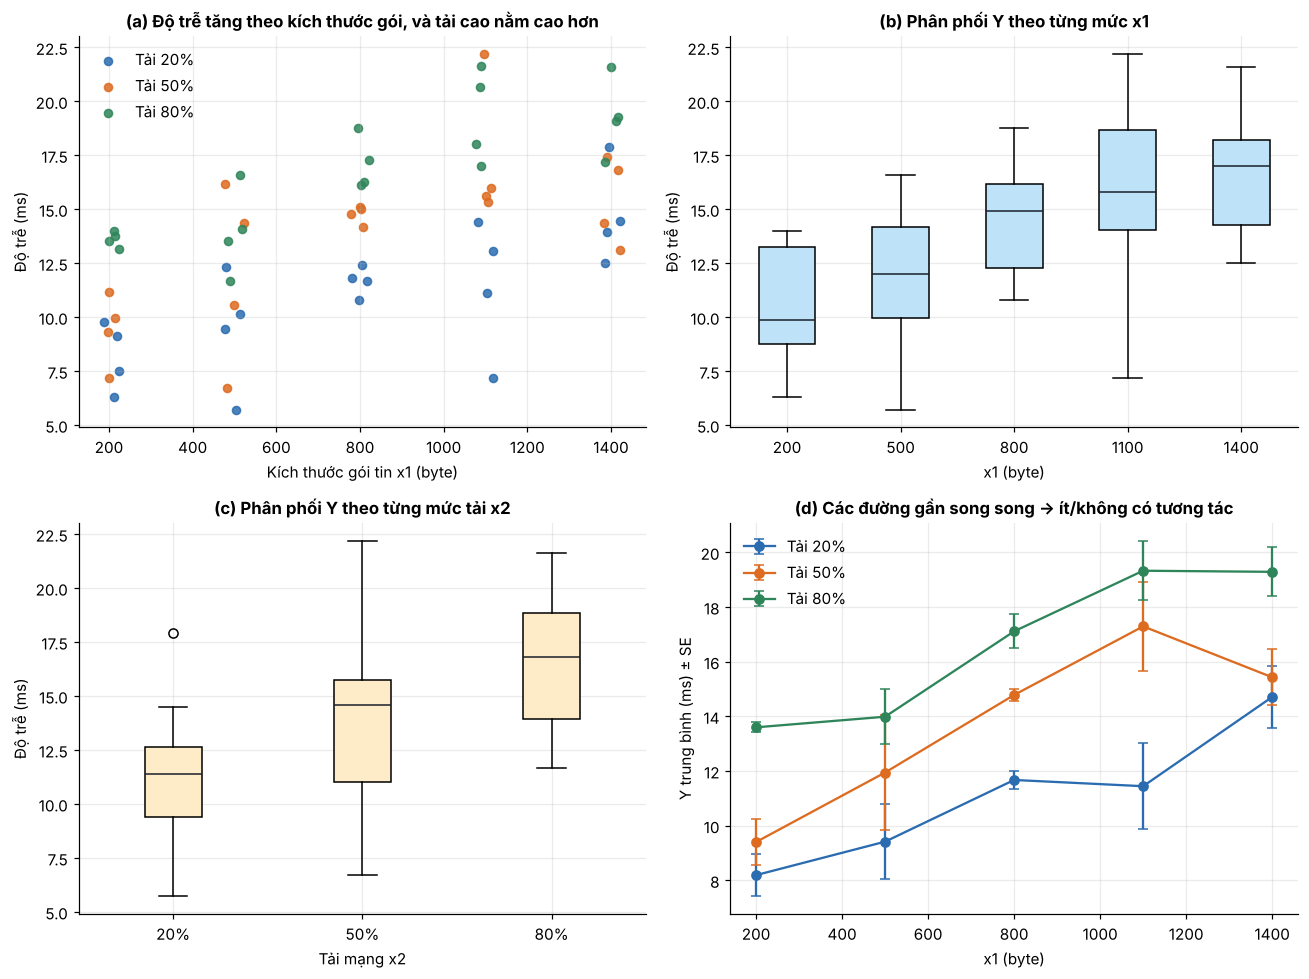

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
cols = {20: C1, 50: C2, 80: C3}
jit = np.random.default_rng(1).uniform(-25, 25, len(df))      # chỉ để các điểm khỏi chồng nhau (thẩm mỹ)

# (a) Y theo x1, tô màu theo tải
for lv in x2_levels:
    s = df[df.x2 == lv]; j = jit[s.index]
    ax[0, 0].scatter(s.x1 + j, s.y, s=28, color=cols[lv], alpha=.85, label=f"Tải {lv}%")
ax[0, 0].set(title="(a) Độ trễ tăng theo kích thước gói, và tải cao nằm cao hơn",
             xlabel="Kích thước gói tin x1 (byte)", ylabel="Độ trễ (ms)"); ax[0, 0].legend()

# (b) Boxplot theo x1
ax[0, 1].boxplot([df[df.x1 == v].y for v in x1_levels], patch_artist=True,
                 boxprops=dict(facecolor="#BEE3F8"), medianprops=dict(color=INK)); ax[0, 1].set_xticklabels(x1_levels)
ax[0, 1].set(title="(b) Phân phối Y theo từng mức x1", xlabel="x1 (byte)", ylabel="Độ trễ (ms)")

# (c) Boxplot theo x2
ax[1, 0].boxplot([df[df.x2 == v].y for v in x2_levels], patch_artist=True,
                 boxprops=dict(facecolor="#FEEBC8"), medianprops=dict(color=INK)); ax[1, 0].set_xticklabels([f"{v}%" for v in x2_levels])
ax[1, 0].set(title="(c) Phân phối Y theo từng mức tải x2", xlabel="Tải mạng x2", ylabel="Độ trễ (ms)")

# (d) Biểu đồ tương tác: trung bình Y theo x1, mỗi đường 1 mức tải
for lv in x2_levels:
    g = df[df.x2 == lv].groupby("x1")["y"]
    ax[1, 1].errorbar(x1_levels, g.mean(), yerr=g.std()/np.sqrt(N_REP), marker="o", capsize=3,
                      color=cols[lv], label=f"Tải {lv}%")
ax[1, 1].set(title="(d) Các đường gần song song → ít/không có tương tác",
             xlabel="x1 (byte)", ylabel="Y trung bình (ms) ± SE"); ax[1, 1].legend()
plt.tight_layout(); savefig("fig01_eda")

**Đọc biểu đồ (lập luận):**
- (a),(b): Y tăng gần tuyến tính theo $x_1$ → mô hình tuyến tính là hợp lý.
- (c): ở mức tải cao, Y cao hơn rõ rệt → $x_2$ cũng là biến quan trọng, **không thể bỏ qua**.
- (a): các điểm cùng một $x_1$ nhưng khác tải **tách thành các "tầng"** — đây chính là phần biến thiên mà mô hình chỉ dùng $x_1$ sẽ bỏ sót và đẩy vào phần dư (xem Mục 5).
- (d): các đường song song → chưa thấy dấu hiệu tương tác; sẽ kiểm định chính thức ở Mục 6.

---
# 3. Hồi quy đơn: chỉ dùng kích thước gói tin  *(Yêu cầu 2)*

**Mô hình:** $Y_i=\beta_0+\beta_1x_{1i}+\epsilon_i$, $\epsilon_i\overset{iid}{\sim}N(0,\sigma^2)$.

**Vì sao chọn hồi quy tuyến tính đơn?** Biến đáp ứng liên tục, biến dự báo định lượng, xu hướng gần thẳng (Mục 2). Ước lượng bằng **bình phương tối thiểu (LS)**:

$$\hat\beta_1=\frac{S_{xy}}{S_{xx}},\qquad \hat\beta_0=\bar y-\hat\beta_1\bar x,\qquad s^2=\frac{SSE}{n-2},\qquad SE(\hat\beta_1)=\sqrt{\frac{s^2}{S_{xx}}}$$

Ta **tự tính tay bằng công thức** (để hiểu bản chất) rồi **đối chiếu với `statsmodels`** (để chắc đúng).

In [9]:
x = df["x1"].to_numpy(float); yv = df["y"].to_numpy(float)
Sxx = ((x - x.mean())**2).sum(); Sxy = ((x - x.mean())*(yv - yv.mean())).sum()
b1_s = Sxy / Sxx
b0_s = yv.mean() - b1_s * x.mean()
res1 = yv - (b0_s + b1_s * x)
SSE1 = (res1**2).sum(); SST = ((yv - yv.mean())**2).sum(); SSR1 = SST - SSE1
s2_1 = SSE1 / (n - 2)
se_b1_s = np.sqrt(s2_1 / Sxx)
se_b0_s = np.sqrt(s2_1 * (1/n + x.mean()**2 / Sxx))

m1 = smf.ols("y ~ x1", data=df).fit()                       # đối chiếu
assert np.allclose([b0_s, b1_s], m1.params) and np.allclose([se_b0_s, se_b1_s], m1.bse)
print("✔ Công thức tay trùng khớp hoàn toàn với statsmodels\n")
print(f"ŷ = {b0_s:.4f} + {b1_s:.6f}·x1")
print(f"SSE = {SSE1:.2f} | SST = {SST:.2f} | R² = {SSR1/SST:.4f} | s = √(SSE/(n-2)) = {np.sqrt(s2_1):.3f} ms")
display(coef_table(m1))

✔ Công thức tay trùng khớp hoàn toàn với statsmodels

ŷ = 9.4675 + 0.005465·x1
SSE = 588.98 | SST = 911.55 | R² = 0.3539 | s = √(SSE/(n-2)) = 3.187 ms


,Hệ số,Sai số chuẩn,t,p-value,CI 95% dưới,CI 95% trên
Intercept,9.46750,0.87808,10.78209,<0.0001,7.70984,11.22516
x1,0.00547,0.00097,5.63600,<0.0001,0.00352,0.00741


→ Mỗi tăng 100 byte kích thước gói, độ trễ TB tăng ≈ 0.547 ms (CI 95%: 0.352 đến 0.741 ms)
→ Mô hình chỉ có x1 giải thích được 35.4% biến thiên của độ trễ; 64.6% còn lại là 'chưa giải thích'.


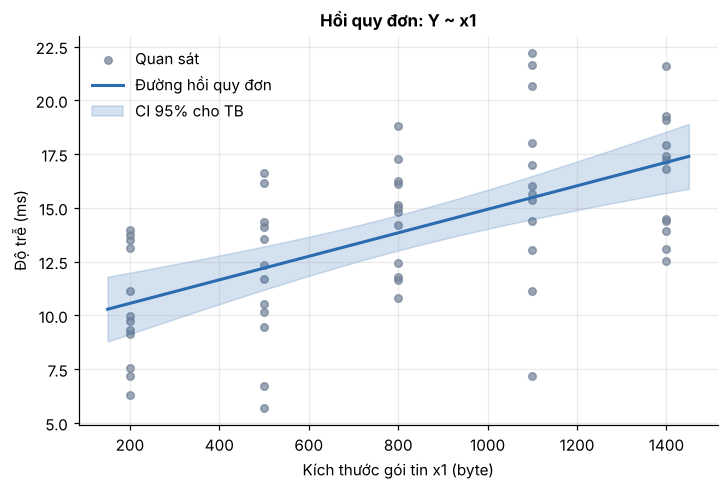

In [10]:
print(f"→ Mỗi tăng 100 byte kích thước gói, độ trễ TB tăng ≈ {100*m1.params['x1']:.3f} ms "
      f"(CI 95%: {100*m1.conf_int().loc['x1',0]:.3f} đến {100*m1.conf_int().loc['x1',1]:.3f} ms)")
print(f"→ Mô hình chỉ có x1 giải thích được {100*m1.rsquared:.1f}% biến thiên của độ trễ; "
      f"{100*(1-m1.rsquared):.1f}% còn lại là 'chưa giải thích'.")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(df.x1, df.y, s=24, color=GREY, alpha=.7, label="Quan sát")
xs = np.linspace(150, 1450, 100); pr = m1.get_prediction(pd.DataFrame({"x1": xs})).summary_frame(ALPHA)
ax.plot(xs, pr["mean"], color=C1, lw=2, label="Đường hồi quy đơn")
ax.fill_between(xs, pr["mean_ci_lower"], pr["mean_ci_upper"], color=C1, alpha=.2, label="CI 95% cho TB")
ax.set(title="Hồi quy đơn: Y ~ x1", xlabel="Kích thước gói tin x1 (byte)", ylabel="Độ trễ (ms)"); ax.legend()
savefig("fig02_simple")

---
# 4. Hồi quy bội: dùng cả hai biến  *(Yêu cầu 3 và 4)*

**Mô hình:** $Y_i=\beta_0+\beta_1x_{1i}+\beta_2x_{2i}+\epsilon_i$. Dạng ma trận: $\hat{\boldsymbol\beta}=(X^\top X)^{-1}X^\top\mathbf y$, $\ \widehat{\text{Var}}(\hat{\boldsymbol\beta})=s^2(X^\top X)^{-1}$, $\ s^2=SSE/(n-3)$.

**Điều kiện áp dụng:** (L) quan hệ tuyến tính, (I) sai số độc lập, (N) sai số chuẩn, (E) phương sai sai số không đổi, và không đa cộng tuyến. Thiết kế ở Mục 1 đảm bảo (I) và không đa cộng tuyến; (L),(N),(E) sẽ được kiểm tra ở Mục 6.

In [11]:
X = np.column_stack([np.ones(n), df["x1"], df["x2"]]).astype(float)
XtX_inv = np.linalg.inv(X.T @ X)
beta = XtX_inv @ X.T @ yv                                   # (X'X)^-1 X'y
res2 = yv - X @ beta
SSE2 = res2 @ res2; s2_2 = SSE2 / (n - 3)
se_beta = np.sqrt(s2_2 * np.diag(XtX_inv))

m2 = smf.ols("y ~ x1 + x2", data=df).fit()
assert np.allclose(beta, m2.params) and np.allclose(se_beta, m2.bse)
print("✔ Công thức ma trận trùng khớp với statsmodels\n")
print(f"ŷ = {beta[0]:.4f} + {beta[1]:.6f}·x1 + {beta[2]:.5f}·x2")
display(coef_table(m2))

✔ Công thức ma trận trùng khớp với statsmodels

ŷ = 4.8212 + 0.005465·x1 + 0.09293·x2


,Hệ số,Sai số chuẩn,t,p-value,CI 95% dưới,CI 95% trên
Intercept,4.82117,0.84219,5.72458,<0.0001,3.13472,6.50762
x1,0.00547,0.00067,8.13089,<0.0001,0.00412,0.00681
x2,0.09293,0.01164,7.98217,<0.0001,0.06961,0.11624


### 4.1 Giải thích từng hệ số — và cụm từ "giữ biến còn lại không đổi"

**Ý nghĩa của "giữ biến còn lại không đổi" (*ceteris paribus*):** $\hat\beta_1$ là mức thay đổi độ trễ trung bình khi $x_1$ tăng 1 đơn vị **với cùng một mức tải $x_2$** (so sánh hai gói có cùng tải mạng). Tương tự $\hat\beta_2$ là tác động của tải **với cùng kích thước gói**. Đây là điểm khác biệt cốt lõi giữa hồi quy bội và hồi quy đơn: hồi quy đơn trộn lẫn mọi thứ, hồi quy bội **tách riêng** từng tác động.

In [12]:
b0, b1, b2 = m2.params[["Intercept", "x1", "x2"]]
ci = m2.conf_int(ALPHA)

# Chứng minh bằng "thí nghiệm tưởng tượng" trên mô hình đã ước lượng
P = lambda a, b: float(m2.predict(pd.DataFrame({"x1": [a], "x2": [b]}))[0])
print("Giữ tải x2 = 50%, tăng x1 từ 800 → 900 byte :", f"{P(900,50)-P(800,50):+.3f} ms   (= 100·β̂1 = {100*b1:.3f})")
print("Giữ x1 = 800 byte, tăng tải x2 từ 50 → 60 % :", f"{P(800,60)-P(800,50):+.3f} ms   (= 10·β̂2  = {10*b2:.3f})")

tab = pd.DataFrame({
    "Hệ số": ["β̂0 (hệ số chặn)", "β̂1 (kích thước gói)", "β̂2 (tải mạng)"],
    "Ước lượng": [b0, b1, b2],
    "Đơn vị": ["ms", "ms / byte", "ms / 1 điểm %"],
    "Diễn giải thực tế": [
        "Độ trễ TB khi x1=0, x2=0 — NGOÀI vùng dữ liệu (200–1400 byte; 20–80%) nên chỉ là 'điểm neo' toán học, không có ý nghĩa vật lý",
        f"+100 byte ⇒ độ trễ TB tăng {100*b1:.2f} ms [{100*ci.loc['x1',0]:.2f}; {100*ci.loc['x1',1]:.2f}], với cùng mức tải",
        f"+10 điểm % tải ⇒ độ trễ TB tăng {10*b2:.2f} ms [{10*ci.loc['x2',0]:.2f}; {10*ci.loc['x2',1]:.2f}], với cùng kích thước gói"]})
pd.set_option("display.max_colwidth", 200); display(tab.round(5))

Giữ tải x2 = 50%, tăng x1 từ 800 → 900 byte : +0.547 ms   (= 100·β̂1 = 0.547)
Giữ x1 = 800 byte, tăng tải x2 từ 50 → 60 % : +0.929 ms   (= 10·β̂2  = 0.929)


,Hệ số,Ước lượng,Đơn vị,Diễn giải thực tế
0,β̂0 (hệ số chặn),4.82117,ms,"Độ trễ TB khi x1=0, x2=0 — NGOÀI vùng dữ liệu (200–1400 byte; 20–80%) nên chỉ là 'điểm neo' toán học, không có ý nghĩa vật lý"
1,β̂1 (kích thước gói),0.00547,ms / byte,"+100 byte ⇒ độ trễ TB tăng 0.55 ms [0.41; 0.68], với cùng mức tải"
2,β̂2 (tải mạng),0.09293,ms / 1 điểm %,"+10 điểm % tải ⇒ độ trễ TB tăng 0.93 ms [0.70; 1.16], với cùng kích thước gói"


**Làm cho hệ số chặn có nghĩa — "tâm hóa" biến.** Trừ các biến cho trung bình ($x_1-\bar x_1,\ x_2-\bar x_2$) thì hệ số chặn trở thành *độ trễ trung bình tại tâm thí nghiệm* (800 byte, 50%) — nằm giữa vùng dữ liệu nên đọc được và có sai số chuẩn nhỏ. Hệ số dốc **không đổi**.

In [13]:
dfc = df.assign(x1c=df.x1 - df.x1.mean(), x2c=df.x2 - df.x2.mean())
m2c = smf.ols("y ~ x1c + x2c", data=dfc).fit()
a = m2c.params["Intercept"]; lo, hi = m2c.conf_int().loc["Intercept"]
print(f"Hệ số chặn sau tâm hóa = {a:.3f} ms, CI 95% [{lo:.3f}; {hi:.3f}] → độ trễ TB tại (x1=800 byte, x2=50%)")
print(f"Hệ số dốc không đổi: {m2c.params['x1c']:.6f} / {m2c.params['x2c']:.5f}")

Hệ số chặn sau tâm hóa = 13.840 ms, CI 95% [13.269; 14.411] → độ trễ TB tại (x1=800 byte, x2=50%)
Hệ số dốc không đổi: 0.005465 / 0.09293


### 4.2 Nhìn thấy "giữ biến còn lại không đổi" bằng hình: biểu đồ hồi quy từng phần (added-variable plot)
Mỗi biểu đồ vẽ **phần dư của Y sau khi loại ảnh hưởng của biến kia** theo **phần dư của biến này sau khi loại ảnh hưởng của biến kia**. Độ dốc của đường trong mỗi hình chính là $\hat\beta_1$ (hoặc $\hat\beta_2$) của mô hình bội.

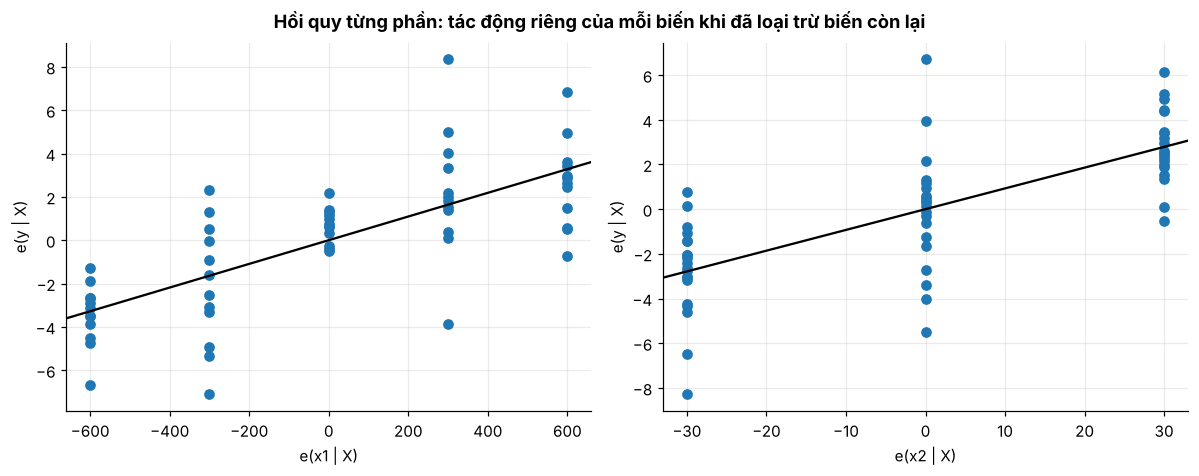

In [14]:
fig = plt.figure(figsize=(11, 4.2))
sm.graphics.plot_partregress_grid(m2, exog_idx=["x1", "x2"], grid=(1, 2), fig=fig)
fig.suptitle("Hồi quy từng phần: tác động riêng của mỗi biến khi đã loại trừ biến còn lại", fontweight="bold", y=1.02)
savefig("fig03_partial")

### 4.3 💡 Phát hiện 1 — "Thiết kế trực giao" làm hệ số dốc *y hệt nhau* giữa hai mô hình
Vì $x_1\perp x_2$ (Mục 1), **hệ số $\hat\beta_1$ của hồi quy đơn bằng đúng $\hat\beta_1$ của hồi quy bội**. Điều khác là **độ bất định được báo cáo** (sai số chuẩn — mô hình đơn thổi phồng vì coi tác động của tải là nhiễu) và **độ phù hợp** ($R^2$). Đây là lợi ích thực của thiết kế cân bằng; ở Mục 10 ta sẽ thấy điều gì xảy ra khi dữ liệu *không* cân bằng (quan sát thực tế).

In [15]:
print(f"β̂1 (hồi quy đơn) = {m1.params['x1']:.8f}")
print(f"β̂1 (hồi quy bội) = {m2.params['x1']:.8f}   → trùng nhau: {np.isclose(m1.params['x1'], m2.params['x1'])}")
print(f"SE(β̂1) đơn = {m1.bse['x1']:.6f}  vs  bội = {m2.bse['x1']:.6f}  "
      f"→ sai số chuẩn của hồi quy bội nhỏ hơn {100*(1-m2.bse['x1']/m1.bse['x1']):.0f}%: mô hình đơn để biến thiên do tải lọt vào 'nhiễu' nên báo cáo độ bất định quá lớn (CI quá rộng)")

β̂1 (hồi quy đơn) = 0.00546508
β̂1 (hồi quy bội) = 0.00546508   → trùng nhau: True
SE(β̂1) đơn = 0.000970  vs  bội = 0.000672  → sai số chuẩn của hồi quy bội nhỏ hơn 31%: mô hình đơn để biến thiên do tải lọt vào 'nhiễu' nên báo cáo độ bất định quá lớn (CI quá rộng)


---
# 5. Kiểm định hệ số, $R^2$ hiệu chỉnh và so sánh phần dư  *(Yêu cầu 5)*

### 5.1 Kiểm định từng hệ số (kiểm định t)
$H_0:\beta_j=0$ (biến $x_j$ không có tác động riêng) và $H_1:\beta_j\ne0$; thống kê $t=\hat\beta_j/SE(\hat\beta_j)\sim t_{n-p}$ dưới $H_0$. Bác bỏ $H_0$ nếu $p<\alpha=0{,}05$.

In [16]:
def verdict(p): return "Bác bỏ H0 → có ý nghĩa" if p < ALPHA else "Không bác bỏ H0"
t_df = pd.DataFrame({
    "Mô hình": ["Đơn", "Bội", "Bội", "Bội"],
    "Hệ số": ["β1 (x1)", "β0 (hệ số chặn)", "β1 (x1)", "β2 (x2)"],
    "t": [m1.tvalues["x1"], m2.tvalues["Intercept"], m2.tvalues["x1"], m2.tvalues["x2"]],
    "bậc tự do": [m1.df_resid, m2.df_resid, m2.df_resid, m2.df_resid],
    "p-value": [fmt_p(m1.pvalues["x1"]), fmt_p(m2.pvalues["Intercept"]), fmt_p(m2.pvalues["x1"]), fmt_p(m2.pvalues["x2"])],
    "Kết luận (α=5%)": [verdict(m1.pvalues["x1"]), verdict(m2.pvalues["Intercept"]), verdict(m2.pvalues["x1"]), verdict(m2.pvalues["x2"])]})
display(t_df.round(3))

print(f"Kiểm định F toàn mô hình bội (H0: β1=β2=0): F = {m2.fvalue:.2f}, p = {fmt_p(m2.f_pvalue)}")

,Mô hình,Hệ số,t,bậc tự do,p-value,Kết luận (α=5%)
0,Đơn,β1 (x1),5.636,58.0,<0.0001,Bác bỏ H0 → có ý nghĩa
1,Bội,β0 (hệ số chặn),5.725,57.0,<0.0001,Bác bỏ H0 → có ý nghĩa
2,Bội,β1 (x1),8.131,57.0,<0.0001,Bác bỏ H0 → có ý nghĩa
3,Bội,β2 (x2),7.982,57.0,<0.0001,Bác bỏ H0 → có ý nghĩa


Kiểm định F toàn mô hình bội (H0: β1=β2=0): F = 64.91, p = <0.0001


### 5.2 So sánh hai mô hình: $R^2$, $R^2$ hiệu chỉnh và phần dư
- $R^2=1-\dfrac{SSE}{SST}$ **luôn tăng** khi thêm biến, kể cả biến vô dụng ⇒ không công bằng để so sánh.
- $R^2_{hc}=1-\dfrac{SSE/(n-p)}{SST/(n-1)}$ **phạt** việc thêm biến (p = số tham số) ⇒ so sánh công bằng. Nếu thêm biến mà $R^2_{hc}$ tăng thì biến đó đáng giữ.
- Kiểm định F từng phần (so sánh mô hình lồng nhau) cho câu trả lời **có/không** về mặt thống kê.

In [17]:
cmp_ = pd.DataFrame({
    "Mô hình": ["Đơn: y ~ x1", "Bội: y ~ x1 + x2"],
    "Số tham số p": [2, 3],
    "SSE (phần dư)": [m1.ssr, m2.ssr],
    "s = RSE (ms)": [np.sqrt(m1.mse_resid), np.sqrt(m2.mse_resid)],
    "R²": [m1.rsquared, m2.rsquared],
    "R² hiệu chỉnh": [m1.rsquared_adj, m2.rsquared_adj],
    "AIC": [m1.aic, m2.aic]}).set_index("Mô hình")
display(cmp_.round(4))

an = anova_lm(m1, m2)
print("\nKiểm định F từng phần: thêm x2 vào mô hình đơn có làm giảm SSE đáng kể không?")
display(an.round(4))
F, pF = an.loc[1, "F"], an.loc[1, "Pr(>F)"]
print(f"→ F = {F:.2f}, p = {fmt_p(pF)} ⇒ {'có' if pF<ALPHA else 'không'} cải thiện đáng kể khi thêm tải mạng.")
print(f"→ R² hiệu chỉnh tăng từ {m1.rsquared_adj:.3f} lên {m2.rsquared_adj:.3f}; "
      f"SSE giảm {100*(1-m2.ssr/m1.ssr):.1f}%; sai số dự đoán điển hình giảm từ {np.sqrt(m1.mse_resid):.2f} xuống {np.sqrt(m2.mse_resid):.2f} ms.")

,Số tham số p,SSE (phần dư),s = RSE (ms),R²,R² hiệu chỉnh,AIC
Mô hình,,,,,,
Đơn: y ~ x1,2,588.9828,3.1867,0.3539,0.3427,311.3158
Bội: y ~ x1 + x2,3,278.1096,2.2089,0.6949,0.6842,268.2929



Kiểm định F từng phần: thêm x2 vào mô hình đơn có làm giảm SSE đáng kể không?


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,58.0,588.9828,0.0,NaN,NaN,NaN
1,57.0,278.1096,1.0,310.8732,63.7151,0.0


→ F = 63.72, p = <0.0001 ⇒ có cải thiện đáng kể khi thêm tải mạng.
→ R² hiệu chỉnh tăng từ 0.343 lên 0.684; SSE giảm 52.8%; sai số dự đoán điển hình giảm từ 3.19 xuống 2.21 ms.


### 5.3 💡 Phát hiện 2 — "Phân rã biến thiên": mỗi yếu tố gánh bao nhiêu phần?
Do thiết kế trực giao, tổng bình phương hồi quy **cộng được chính xác**: $SST=SSR_{x_1}+SSR_{x_2}+SSE$. Ta có thể nói rất cụ thể: *"x1 giải thích a%, x2 giải thích b%, còn c% là nhiễu ngẫu nhiên"*. Ngoài ra so sánh **tác động trên toàn dải khảo sát** (hệ số × độ rộng dải) cho biết yếu tố nào quan trọng hơn — công bằng hơn so sánh hệ số thô vì đơn vị khác nhau.

SSR(x1) + SSR(x2) = 633.44  |  SSR(x1,x2) = 633.44  → cộng được (trực giao): True


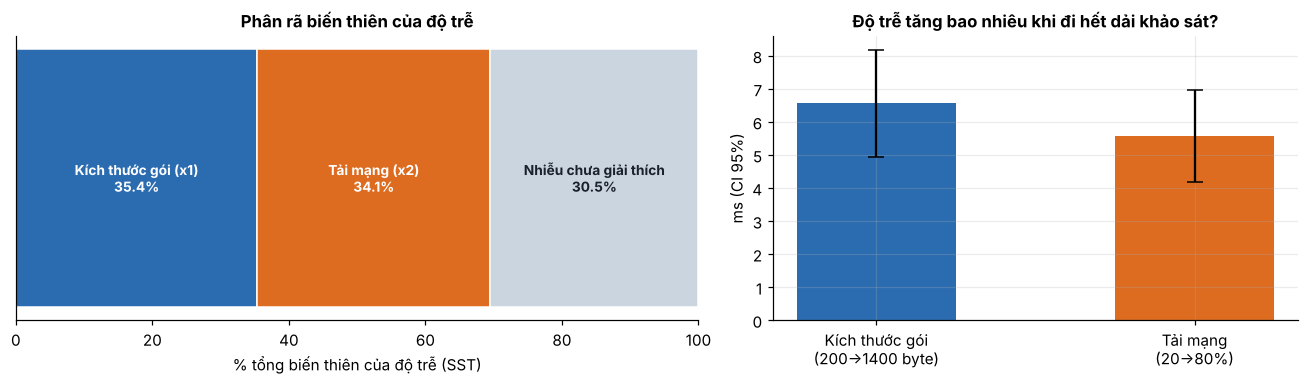

    hệ số  độ rộng dải  tác động toàn dải (ms)
x1  0.005         1200                   6.558
x2  0.093           60                   5.576


In [18]:
m_x2 = smf.ols("y ~ x2", data=df).fit()
SSR_x1, SSR_x2 = m1.ess, m_x2.ess
SSR_both = m2.ess
print(f"SSR(x1) + SSR(x2) = {SSR_x1+SSR_x2:.2f}  |  SSR(x1,x2) = {SSR_both:.2f}  → cộng được (trực giao): {np.isclose(SSR_x1+SSR_x2, SSR_both)}")

parts = pd.Series({"Kích thước gói (x1)": SSR_x1/SST, "Tải mạng (x2)": SSR_x2/SST, "Nhiễu chưa giải thích": m2.ssr/SST})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
left = 0
for (k, v), c in zip(parts.items(), [C1, C2, "#CBD5E0"]):
    ax[0].barh([0], [v*100], left=left, color=c, edgecolor="white", height=.5)
    ax[0].text(left + v*50, 0, f"{k}\n{v*100:.1f}%", ha="center", va="center", color="white" if c != "#CBD5E0" else INK, fontsize=9, fontweight="bold")
    left += v*100
ax[0].set(xlim=(0, 100), yticks=[], xlabel="% tổng biến thiên của độ trễ (SST)", title="Phân rã biến thiên của độ trễ"); ax[0].grid(False)

rg1, rg2 = np.ptp(x1_levels), np.ptp(x2_levels)
eff = pd.DataFrame({"hệ số": [m2.params["x1"], m2.params["x2"]], "độ rộng dải": [rg1, rg2]}, index=["x1", "x2"])
eff["tác động toàn dải (ms)"] = eff["hệ số"] * eff["độ rộng dải"]
elo = m2.conf_int().loc[["x1", "x2"]] .mul([rg1, rg2], axis=0)
ax[1].bar(["Kích thước gói\n(200→1400 byte)", "Tải mạng\n(20→80%)"], eff["tác động toàn dải (ms)"], color=[C1, C2], width=.5,
          yerr=[eff["tác động toàn dải (ms)"].values - elo[0].values, elo[1].values - eff["tác động toàn dải (ms)"].values], capsize=5)
ax[1].set(title="Độ trễ tăng bao nhiêu khi đi hết dải khảo sát?", ylabel="ms (CI 95%)")
plt.tight_layout(); savefig("fig04_decomposition")
print(eff.round(3))

### 5.4 💡 Phát hiện 3 — Phần dư "nói" mô hình đơn đã bỏ sót điều gì
Nếu mô hình thiếu một biến quan trọng, phần dư của nó sẽ **mang cấu trúc** (không còn là nhiễu thuần túy). Ta kiểm tra bằng:
1. Biểu đồ phần dư theo mức tải $x_2$ của cả hai mô hình;
2. **Kiểm định Kruskal–Wallis (Chương 7)** — phi tham số, không cần giả định chuẩn — để hỏi: *"phần dư có cùng vị trí ở cả 3 mức tải không?"* ($H_0$: cùng vị trí). Mô hình tốt thì **không** bác bỏ $H_0$.

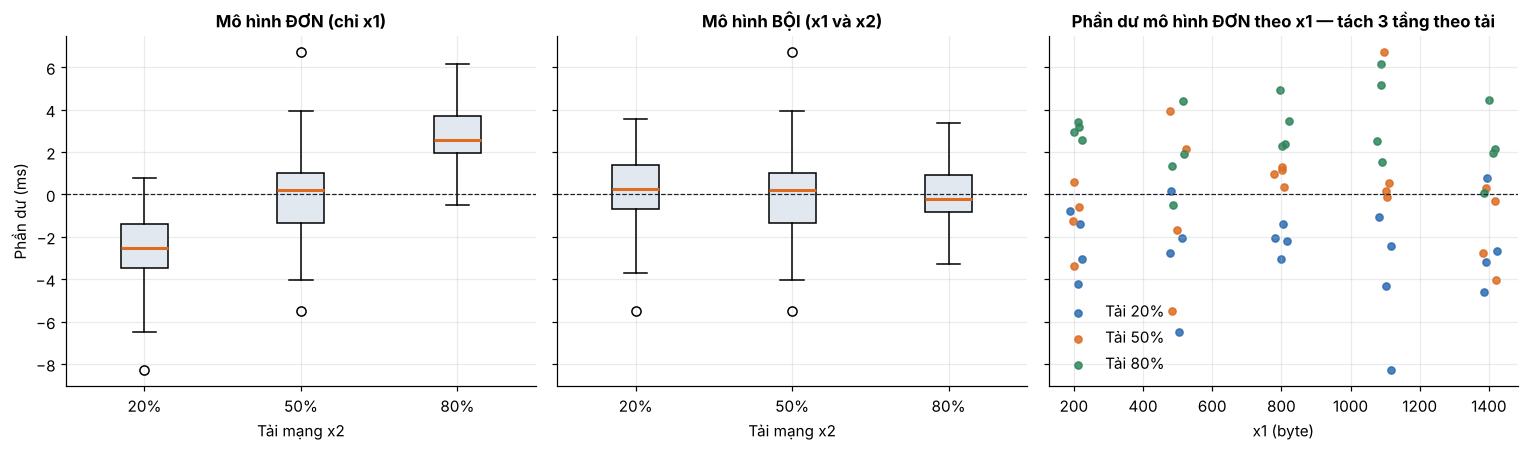

Kruskal–Wallis phần dư MÔ HÌNH ĐƠN theo mức tải: H = 35.06, p = <0.0001 → Bác bỏ H0: phần dư còn cấu trúc (thiếu biến tải mạng)
Kruskal–Wallis phần dư MÔ HÌNH BỘI theo mức tải: H = 0.20, p = 0.9057 → Không bác bỏ H0: phần dư đã là nhiễu thuần túy

Độ lệch chuẩn phần dư: đơn = 3.160 ms ; bội = 2.171 ms


In [19]:
df["res1"], df["res2"] = m1.resid, m2.resid
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for a_, (col, ttl) in zip(ax[:2], [("res1", "Mô hình ĐƠN (chỉ x1)"), ("res2", "Mô hình BỘI (x1 và x2)")]):
    a_.boxplot([df[df.x2 == v][col] for v in x2_levels], patch_artist=True,
               boxprops=dict(facecolor="#E2E8F0"), medianprops=dict(color=C2, lw=2)); a_.set_xticklabels([f"{v}%" for v in x2_levels])
    a_.axhline(0, color=INK, lw=.8, ls="--"); a_.set(title=ttl, xlabel="Tải mạng x2")
ax[0].set_ylabel("Phần dư (ms)")
for lv in x2_levels:
    s = df[df.x2 == lv]; ax[2].scatter(s.x1 + jit[s.index], s.res1, s=22, color=cols[lv], label=f"Tải {lv}%", alpha=.85)
ax[2].axhline(0, color=INK, lw=.8, ls="--"); ax[2].set(title="Phần dư mô hình ĐƠN theo x1 — tách 3 tầng theo tải", xlabel="x1 (byte)"); ax[2].legend()
plt.tight_layout(); savefig("fig05_residuals_by_load")

kw1 = stats.kruskal(*[df[df.x2 == v]["res1"] for v in x2_levels])
kw2 = stats.kruskal(*[df[df.x2 == v]["res2"] for v in x2_levels])
print(f"Kruskal–Wallis phần dư MÔ HÌNH ĐƠN theo mức tải: H = {kw1.statistic:.2f}, p = {fmt_p(kw1.pvalue)} → {'Bác bỏ H0: phần dư còn cấu trúc (thiếu biến tải mạng)' if kw1.pvalue<ALPHA else 'Không bác bỏ'}")
print(f"Kruskal–Wallis phần dư MÔ HÌNH BỘI theo mức tải: H = {kw2.statistic:.2f}, p = {fmt_p(kw2.pvalue)} → {'Bác bỏ H0' if kw2.pvalue<ALPHA else 'Không bác bỏ H0: phần dư đã là nhiễu thuần túy'}")
print(f"\nĐộ lệch chuẩn phần dư: đơn = {df.res1.std():.3f} ms ; bội = {df.res2.std():.3f} ms")

---
# 6. Kiểm tra giả định và kiểm chứng bằng phương pháp phi tham số (Chương 7)

Kết luận từ hồi quy chỉ đáng tin nếu các giả định được thỏa. Ta kiểm tra **từng giả định bằng cả hình và kiểm định**:

| Giả định | Cách kiểm tra |
|---|---|
| Tuyến tính | Kiểm định thiếu khớp *lack-of-fit* (nhờ có lặp) |
| Chuẩn của sai số | Q–Q plot + Shapiro–Wilk |
| Phương sai không đổi | Phần dư–giá trị khớp + Breusch–Pagan |
| Độc lập | Phần dư theo thứ tự đo + Durbin–Watson |
| Điểm ảnh hưởng | Khoảng cách Cook |

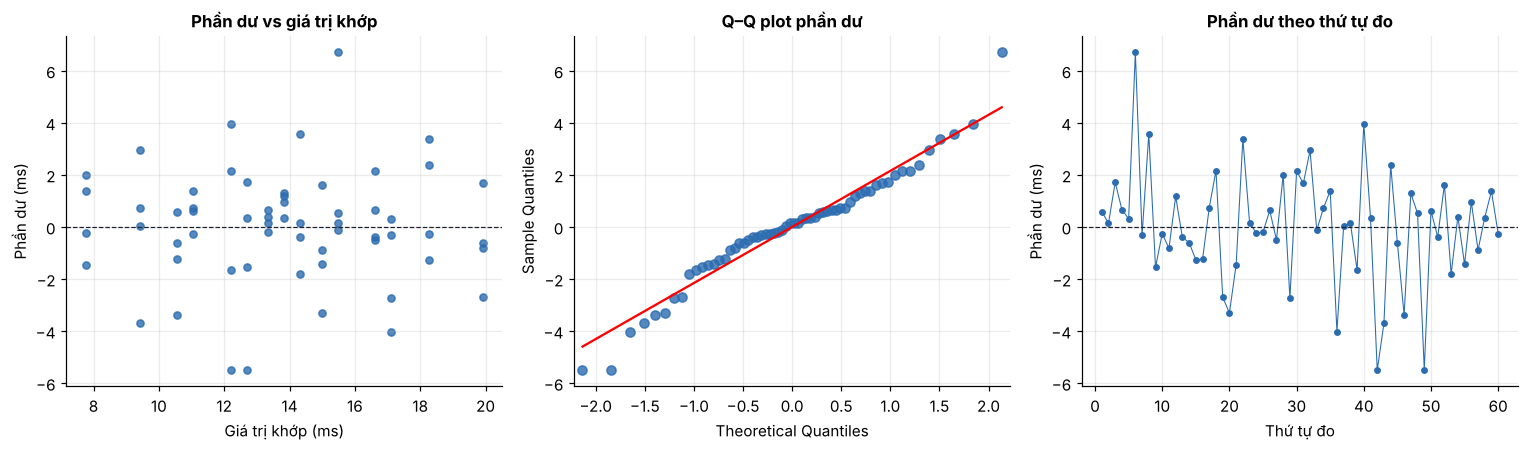

,Giả định,Thống kê,p-value,Kết luận (α=5%)
0,Tuyến tính (lack-of-fit F),F = 0.90,0.5504,Đạt
1,Tương tác x1×x2,t = 0.33,0.7410,Không có tương tác
2,Chuẩn (Shapiro–Wilk),W = 0.968,0.1170,Đạt
3,Phương sai không đổi (Breusch–Pagan),LM = 0.92,0.6321,Đạt
4,Độc lập (Durbin–Watson ≈ 2),DW = 2.15,—,Đạt
5,"Điểm ảnh hưởng (Cook max < 0,5)",max D = 0.115,—,Đạt


In [20]:
# --- Hình chẩn đoán ---
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
ax[0].scatter(m2.fittedvalues, m2.resid, s=22, color=C1, alpha=.8); ax[0].axhline(0, color=INK, ls="--", lw=.8)
ax[0].set(title="Phần dư vs giá trị khớp", xlabel="Giá trị khớp (ms)", ylabel="Phần dư (ms)")
sm.qqplot(m2.resid, line="s", ax=ax[1], markerfacecolor=C1, markeredgecolor=C1, alpha=.8); ax[1].set_title("Q–Q plot phần dư")
ax[2].plot(df["run"], m2.resid, marker="o", ms=3.5, lw=.7, color=C1); ax[2].axhline(0, color=INK, ls="--", lw=.8)
ax[2].set(title="Phần dư theo thứ tự đo", xlabel="Thứ tự đo", ylabel="Phần dư (ms)")
plt.tight_layout(); savefig("fig06_diagnostics")

# --- Kiểm định ---
sw  = stats.shapiro(m2.resid)
bp  = het_breuschpagan(m2.resid, m2.model.exog)
dw  = durbin_watson(m2.resid.values[np.argsort(df["run"].values)])
m_cell = smf.ols("y ~ C(x1) * C(x2)", data=df).fit()               # mô hình "tự do": mỗi tổ hợp một trung bình
lof = anova_lm(m2, m_cell)                                          # lack-of-fit F
m_int = smf.ols("y ~ x1 * x2", data=df).fit(); p_int = m_int.pvalues["x1:x2"]
infl = m2.get_influence(); cook = infl.cooks_distance[0]

diag = pd.DataFrame([
    ["Tuyến tính (lack-of-fit F)",       f"F = {lof.loc[1,'F']:.2f}",  fmt_p(lof.loc[1,'Pr(>F)']), "Đạt" if lof.loc[1,'Pr(>F)']>ALPHA else "Không đạt"],
    ["Tương tác x1×x2",                  f"t = {m_int.tvalues['x1:x2']:.2f}", fmt_p(p_int),            "Không có tương tác" if p_int>ALPHA else "Có tương tác"],
    ["Chuẩn (Shapiro–Wilk)",             f"W = {sw.statistic:.3f}",    fmt_p(sw.pvalue),            "Đạt" if sw.pvalue>ALPHA else "Không đạt"],
    ["Phương sai không đổi (Breusch–Pagan)", f"LM = {bp[0]:.2f}",      fmt_p(bp[1]),                "Đạt" if bp[1]>ALPHA else "Không đạt"],
    ["Độc lập (Durbin–Watson ≈ 2)",      f"DW = {dw:.2f}",             "—",                         "Đạt" if 1.5<dw<2.5 else "Cần xem lại"],
    ["Điểm ảnh hưởng (Cook max < 0,5)",  f"max D = {cook.max():.3f}",  "—",                         "Đạt" if cook.max()<.5 else "Có điểm đáng ngờ"]],
    columns=["Giả định", "Thống kê", "p-value", "Kết luận (α=5%)"])
display(diag)

**Đọc kết quả:** bảng trên cho biết mô hình tuyến tính–không tương tác có phù hợp với dữ liệu hay không. Kiểm định *lack-of-fit* là điểm mạnh nhờ thiết kế có lặp: nó so sánh mô hình thẳng với mô hình "tự do" (mỗi ô một trung bình riêng) — nếu không bác bỏ thì **không có bằng chứng cong hay tương tác** trong dải khảo sát.

### Kiểm chứng độ vững bằng phương pháp phi tham số (Chương 7)
Dùng khi không muốn phụ thuộc vào giả định chuẩn:
1. **Wilcoxon hạng có dấu** cho phần dư: $H_0$: trung vị phần dư $=0$ (mô hình không lệch có hệ thống).
2. **Wilcoxon–Mann–Whitney**: so sánh Y giữa tải 80% và 20% (mỗi nhóm 20 quan sát); kèm ước lượng dịch chuyển Hodges–Lehmann.
3. **Kruskal–Wallis + so sánh từng cặp (hiệu chỉnh Holm)**: Y có khác nhau giữa 5 mức kích thước gói không? *(Thiết kế cân bằng nên mỗi mức $x_1$ gặp đủ 3 mức tải → so sánh không bị nhiễu bởi tải.)*
4. **Bootstrap cặp** cho CI của $\hat\beta_1,\hat\beta_2$ (không dùng công thức chuẩn) — mỗi lần lấy một mẫu mới có hoàn lại.

In [21]:
# 1) Wilcoxon signed-rank cho phần dư
w = stats.wilcoxon(m2.resid)
print(f"[1] Wilcoxon hạng có dấu — phần dư mô hình bội: W = {w.statistic:.0f}, p = {fmt_p(w.pvalue)} "
      f"→ {'không bác bỏ: trung vị phần dư ≈ 0' if w.pvalue>ALPHA else 'bác bỏ H0'}")

# 2) Mann–Whitney: tải 80% vs 20%
hi_, lo_ = df[df.x2 == 80]["y"].to_numpy(), df[df.x2 == 20]["y"].to_numpy()
mw = stats.mannwhitneyu(hi_, lo_, alternative="greater")
hl = np.median((hi_[:, None] - lo_[None, :]).ravel())               # ước lượng Hodges–Lehmann
bg = np.random.default_rng(SEED + 1)
hl_boot = [np.median((bg.choice(hi_, len(hi_))[:, None] - bg.choice(lo_, len(lo_))[None, :]).ravel()) for _ in range(3000)]
print(f"[2] Mann–Whitney (80% > 20%): U = {mw.statistic:.0f}, p = {fmt_p(mw.pvalue)}; "
      f"độ trễ cao hơn khoảng {hl:.2f} ms (Hodges–Lehmann; CI bootstrap 95%: {np.percentile(hl_boot,2.5):.2f}–{np.percentile(hl_boot,97.5):.2f})")

# 3) Kruskal–Wallis + so sánh cặp có hiệu chỉnh Holm
kw = stats.kruskal(*[df[df.x1 == v]["y"] for v in x1_levels])
print(f"[3] Kruskal–Wallis Y theo 5 mức x1: H = {kw.statistic:.2f}, p = {fmt_p(kw.pvalue)}")
pairs, ps = [], []
for i in range(5):
    for j in range(i+1, 5):
        u = stats.mannwhitneyu(df[df.x1 == x1_levels[j]]["y"], df[df.x1 == x1_levels[i]]["y"], alternative="two-sided")
        pairs.append(f"{x1_levels[j]} vs {x1_levels[i]}"); ps.append(u.pvalue)
adj = multipletests(ps, method="holm")[1]
pw = pd.DataFrame({"Cặp mức x1 (byte)": pairs, "p thô": [fmt_p(p) for p in ps], "p Holm": [fmt_p(p) for p in adj],
                   "Khác biệt (α=5%)": ["Có" if p < ALPHA else "Không" for p in adj]})
display(pw)

# 4) Bootstrap cặp cho hệ số hồi quy bội
bs = np.random.default_rng(SEED + 2); B = 5000; bb = np.empty((B, 3))
for k in range(B):
    idx = bs.integers(0, n, n); bb[k] = np.linalg.lstsq(X[idx], yv[idx], rcond=None)[0]
boot_ci = pd.DataFrame(np.percentile(bb, [2.5, 97.5], axis=0).T, index=["β0", "β1 (x1)", "β2 (x2)"], columns=["Bootstrap 2,5%", "Bootstrap 97,5%"])
boot_ci["t-CI dưới"] = m2.conf_int().values[:, 0]; boot_ci["t-CI trên"] = m2.conf_int().values[:, 1]
print("\n[4] So sánh CI 95% theo bootstrap (không cần giả định chuẩn) và theo t:")
display(boot_ci.round(5))

[1] Wilcoxon hạng có dấu — phần dư mô hình bội: W = 873, p = 0.7572 → không bác bỏ: trung vị phần dư ≈ 0
[2] Mann–Whitney (80% > 20%): U = 363, p = <0.0001; độ trễ cao hơn khoảng 5.56 ms (Hodges–Lehmann; CI bootstrap 95%: 3.70–7.43)
[3] Kruskal–Wallis Y theo 5 mức x1: H = 23.26, p = 0.0001


,Cặp mức x1 (byte),p thô,p Holm,Khác biệt (α=5%)
0,500 vs 200,0.2145,0.6435,Không
1,800 vs 200,0.0017,0.0149,Có
2,1100 vs 200,0.0024,0.0171,Có
3,1400 vs 200,0.0003,0.0031,Có
4,800 vs 500,0.0464,0.2319,Không
5,1100 vs 500,0.0166,0.0994,Không
6,1400 vs 500,0.0020,0.0161,Có
7,1100 vs 800,0.2855,0.6435,Không
8,1400 vs 800,0.1124,0.4494,Không
9,1400 vs 1100,0.9310,0.9310,Không



[4] So sánh CI 95% theo bootstrap (không cần giả định chuẩn) và theo t:


,"Bootstrap 2,5%","Bootstrap 97,5%",t-CI dưới,t-CI trên
β0,3.26916,6.22783,3.13472,6.50762
β1 (x1),0.00427,0.00674,0.00412,0.00681
β2 (x2),0.07378,0.11225,0.06961,0.11624


**Kết luận mục 6:** nếu các kiểm định phi tham số và bootstrap **cho cùng kết luận** với hồi quy (tải cao ⇒ trễ cao; kích thước tăng ⇒ trễ tăng; CI bootstrap ≈ CI t), thì kết luận **vững**, không phụ thuộc vào một giả định riêng nào. Đây là cách ta nối Chương 6 (tham số) với Chương 7 (phi tham số).

---
# 7. Dự đoán độ trễ: $x_1=1000$ byte, $x_2=60\%$  *(Yêu cầu 6)*

Có **hai** loại khoảng cần phân biệt (hay bị nhầm):

| Khoảng | Trả lời câu hỏi | Công thức | Độ rộng |
|---|---|---|---|
| **CI 95% cho trung bình** | "Độ trễ **trung bình** của *mọi* gói như vậy là bao nhiêu?" | $\hat y_0\pm t\,s\sqrt{\mathbf x_0^\top(X^\top X)^{-1}\mathbf x_0}$ | hẹp |
| **PI 95% cho một quan sát mới** | "Một gói **cụ thể** sắp gửi sẽ trễ bao nhiêu?" | $\hat y_0\pm t\,s\sqrt{1+\mathbf x_0^\top(X^\top X)^{-1}\mathbf x_0}$ | rộng hơn (cộng thêm $\sigma^2$ của nhiễu) |

**Lưu ý điều kiện:** (1000; 60%) **không** nằm trong 15 tổ hợp đã đo nhưng nằm **bên trong** dải khảo sát ⇒ là *nội suy* (an toàn nếu quan hệ thẳng — đã kiểm tra bằng lack-of-fit ở Mục 6), khác với *ngoại suy*.

In [22]:
x0 = np.array([1, 1000, 60.0])
y0 = x0 @ beta
h0 = x0 @ XtX_inv @ x0                                              # đòn bẩy của điểm cần dự đoán
tcrit = stats.t.ppf(1 - ALPHA/2, n - 3); s = np.sqrt(s2_2)
ci_m = (y0 - tcrit*s*np.sqrt(h0),     y0 + tcrit*s*np.sqrt(h0))
pi_o = (y0 - tcrit*s*np.sqrt(1 + h0), y0 + tcrit*s*np.sqrt(1 + h0))

new = pd.DataFrame({"x1": [1000], "x2": [60]})
sf = m2.get_prediction(new).summary_frame(ALPHA)
assert np.allclose([sf["mean"][0], sf["mean_ci_lower"][0], sf["obs_ci_lower"][0]], [y0, ci_m[0], pi_o[0]])
print("✔ Công thức tay khớp với statsmodels\n")
print(f"Dự đoán điểm : ŷ = {beta[0]:.3f} + {beta[1]:.5f}×1000 + {beta[2]:.4f}×60 = {y0:.2f} ms")
print(f"CI 95% cho độ trễ TRUNG BÌNH : [{ci_m[0]:.2f} ; {ci_m[1]:.2f}] ms  (rộng {ci_m[1]-ci_m[0]:.2f})")
print(f"PI 95% cho MỘT gói mới       : [{pi_o[0]:.2f} ; {pi_o[1]:.2f}] ms  (rộng {pi_o[1]-pi_o[0]:.2f})")

# So sánh: nếu chỉ dùng mô hình đơn (bỏ qua tải)
sf1 = m1.get_prediction(new).summary_frame(ALPHA)
print(f"\nNếu chỉ dùng mô hình ĐƠN: ŷ = {sf1['mean'][0]:.2f} ms, PI 95% = [{sf1['obs_ci_lower'][0]:.2f} ; {sf1['obs_ci_upper'][0]:.2f}] "
      f"(rộng {sf1['obs_ci_upper'][0]-sf1['obs_ci_lower'][0]:.2f}) → khoảng dự đoán RỘNG hơn {100*((sf1['obs_ci_upper'][0]-sf1['obs_ci_lower'][0])/(pi_o[1]-pi_o[0])-1):.0f}% vì bỏ sót tải mạng "
      f"và không biết gói đang chạy ở tải 60% (mô hình đơn coi như tải trung bình).")

✔ Công thức tay khớp với statsmodels

Dự đoán điểm : ŷ = 4.821 + 0.00547×1000 + 0.0929×60 = 15.86 ms
CI 95% cho độ trễ TRUNG BÌNH : [15.19 ; 16.53] ms  (rộng 1.35)
PI 95% cho MỘT gói mới       : [11.39 ; 20.34] ms  (rộng 8.95)

Nếu chỉ dùng mô hình ĐƠN: ŷ = 14.93 ms, PI 95% = [8.49 ; 21.38] (rộng 12.89) → khoảng dự đoán RỘNG hơn 44% vì bỏ sót tải mạng và không biết gói đang chạy ở tải 60% (mô hình đơn coi như tải trung bình).


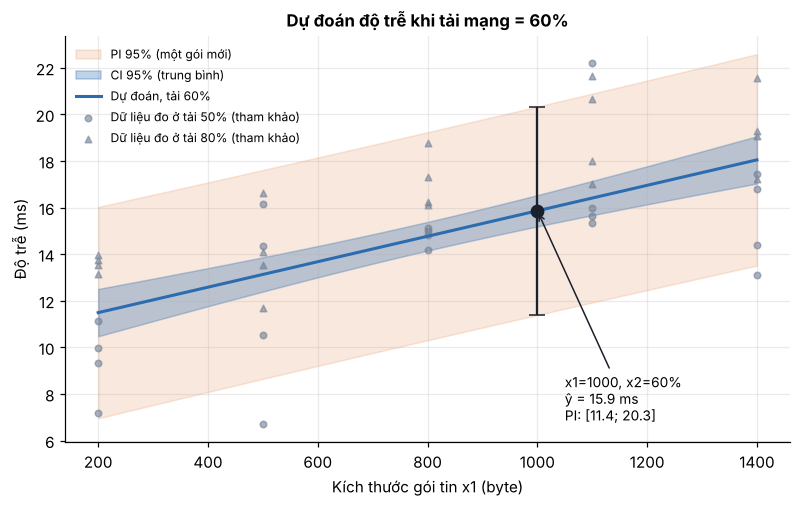

In [23]:
xs = np.linspace(200, 1400, 120)
grid = pd.DataFrame({"x1": xs, "x2": 60})
g = m2.get_prediction(grid).summary_frame(ALPHA)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.fill_between(xs, g["obs_ci_lower"], g["obs_ci_upper"], color=C2, alpha=.15, label="PI 95% (một gói mới)")
ax.fill_between(xs, g["mean_ci_lower"], g["mean_ci_upper"], color=C1, alpha=.30, label="CI 95% (trung bình)")
ax.plot(xs, g["mean"], color=C1, lw=2, label="Dự đoán, tải 60%")
sub = df[df.x2 == 50]; ax.scatter(sub.x1, sub.y, s=18, color=GREY, alpha=.6, label="Dữ liệu đo ở tải 50% (tham khảo)")
sub = df[df.x2 == 80]; ax.scatter(sub.x1, sub.y, s=18, color=GREY, alpha=.6, marker="^", label="Dữ liệu đo ở tải 80% (tham khảo)")
ax.errorbar([1000], [y0], yerr=[[y0 - pi_o[0]], [pi_o[1] - y0]], fmt="o", color=INK, ms=8, capsize=5, zorder=5)
ax.annotate(f"x1=1000, x2=60%\nŷ = {y0:.1f} ms\nPI: [{pi_o[0]:.1f}; {pi_o[1]:.1f}]", (1000, y0), (1050, y0 - 9), fontsize=9,
            arrowprops=dict(arrowstyle="->", color=INK))
ax.set(title="Dự đoán độ trễ khi tải mạng = 60%", xlabel="Kích thước gói tin x1 (byte)", ylabel="Độ trễ (ms)"); ax.legend(loc="upper left", fontsize=8)
savefig("fig07_prediction")

---
# 8. Yếu tố thực tế chưa được mô hình xét đến & giới hạn áp dụng  *(Yêu cầu 7)*

### 8.1 Mô hình hiện tại ngầm giả định gì?
$$\text{Độ trễ}=\text{hằng số}+\underbrace{\beta_1\cdot\text{kích thước}}_{\text{tuyến tính}}+\underbrace{\beta_2\cdot\text{tải}}_{\text{tuyến tính}}+\text{nhiễu chuẩn, phương sai cố định}$$
Thực tế mạng **phức tạp hơn** theo bốn nhóm:

| Nhóm | Yếu tố thực tế | Hệ quả lên mô hình |
|---|---|---|
| **A. Biến bị bỏ sót** | Số chặng (hop) & khoảng cách (trễ lan truyền); băng thông liên kết; kích thước bộ đệm/hàng đợi; giao thức (TCP/UDP, bắt tay); tỉ lệ mất gói & truyền lại; xử lý ở máy chủ (CPU); loại liên kết (Wi‑Fi/cáp quang/4G); ưu tiên QoS; giờ trong ngày | Hệ số hiện tại có thể "hút" tác động của biến ẩn nếu biến ẩn tương quan với $x_1,x_2$ → **thiên lệch** (Mục 10B) |
| **B. Phi tuyến** | Lý thuyết hàng đợi: trễ chờ $\propto 1/(1-\rho)$ → tăng vọt khi tải $\to100\%$ (xem hình dưới) | Đường thẳng **đánh giá thấp** trễ ở tải cao; không ngoại suy được |
| **C. Tương tác** | Gói lớn bị ảnh hưởng nhiều hơn khi tải cao (hàng đợi + thời gian truyền) | Hệ số "không đổi" chỉ đúng khi không có tương tác (Mục 6 chưa thấy, nhưng dữ liệu thật có thể khác) |
| **D. Tính chất thống kê** | Phương sai tăng theo tải (heteroscedasticity); nhiễu lệch phải và có đuôi dài (spike/jitter) thay vì chuẩn; tự tương quan theo thời gian; điểm ngoại lai do nghẽn tức thời | Khoảng tin cậy/dự đoán sai độ rộng; PI đối xứng không phản ánh đuôi dài |

### 8.2 Minh họa giới hạn: vì sao *không ngoại suy* ra ngoài dải 20–80%
Hình dưới là **mô hình lý thuyết hàng đợi M/M/1 (minh họa khái niệm, không phải dữ liệu của nhóm)**: ta khớp một đường thẳng trên đúng dải 20–80% như thiết kế thí nghiệm rồi xem nó sai thế nào khi tải lên 90–95%.

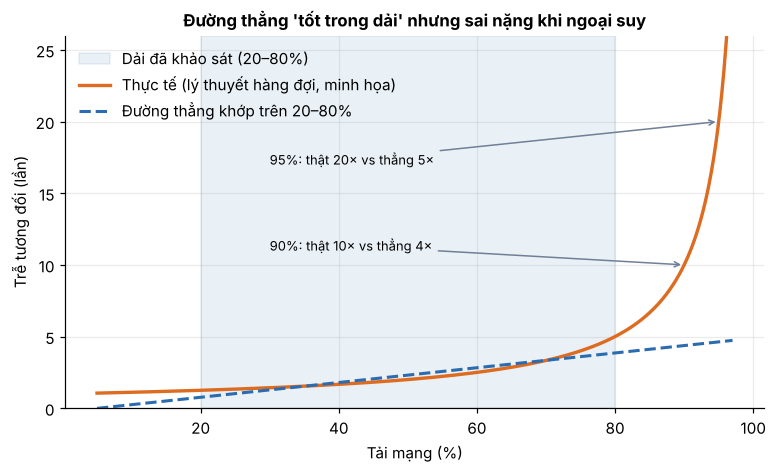

Tại tải 95%: đường thẳng dự đoán 4.6 lần, thực tế 20 lần → đánh giá thấp 77%.


In [24]:
rho = np.linspace(0.05, 0.97, 300); delay = 1 / (1 - rho)              # trễ tương đối theo lý thuyết M/M/1
msk = (rho >= .20) & (rho <= .80); k1, k0 = np.polyfit(rho[msk], delay[msk], 1)
fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.axvspan(20, 80, color=C1, alpha=.10, label="Dải đã khảo sát (20–80%)")
ax.plot(rho*100, delay, color=C2, lw=2.2, label="Thực tế (lý thuyết hàng đợi, minh họa)")
ax.plot(rho*100, k0 + k1*rho, color=C1, lw=2, ls="--", label="Đường thẳng khớp trên 20–80%")
for r in (.9, .95):
    ax.annotate(f"{r:.0%}: thật {1/(1-r):.0f}× vs thẳng {k0+k1*r:.0f}×", (r*100, 1/(1-r)), (30, 17 if r==.95 else 11), fontsize=8.5, arrowprops=dict(arrowstyle="->", color=GREY))
ax.set(ylim=(0, 26), title="Đường thẳng 'tốt trong dải' nhưng sai nặng khi ngoại suy", xlabel="Tải mạng (%)", ylabel="Trễ tương đối (lần)"); ax.legend(loc="upper left")
savefig("fig08_limits")
print(f"Tại tải 95%: đường thẳng dự đoán {k0+k1*.95:.1f} lần, thực tế {1/(1-.95):.0f} lần → đánh giá thấp {100*(1-(k0+k1*.95)/20):.0f}%.")

### 8.3 Giới hạn khi áp dụng kết quả (khuyến nghị sử dụng)
1. **Phạm vi:** chỉ dùng cho $x_1\in[200;1400]$ byte và $x_2\in[20;80]\%$. Ngoài dải → cần đo thêm; đặc biệt tải $>80\%$ phi tuyến mạnh.
2. **Dữ liệu mô phỏng:** hệ số là **minh họa phương pháp**, không phải đặc tính của một mạng thực nào. Khi áp dụng thật phải đo lại.
3. **Nhân quả:** thí nghiệm có kiểm soát ⇒ diễn giải "tăng x1 gây tăng trễ" hợp lý; với dữ liệu quan sát (giám sát mạng hằng ngày) chỉ nên nói "có liên hệ" vì tải và kích thước thường đi cùng nhau (Mục 10B).
4. **Dự đoán cá thể** có sai số điển hình ≈ ±4,5 ms (PI) — không dùng được cho cam kết SLA chặt (ví dụ < 1 ms).
5. **Cỡ mẫu n = 60** đủ cho hệ số chính nhưng yếu cho việc phát hiện tương tác nhỏ hoặc phi tuyến nhẹ.

---
# 9. Kết luận bắt buộc: biến cần thu thập để xây dựng mô hình dự đoán độ trễ tốt hơn

Dựa trên các giới hạn ở Mục 8, nhóm đề xuất thu thập (xếp theo thứ tự ưu tiên):

In [25]:
need = pd.DataFrame([
 [1, "Băng thông / dung lượng liên kết (Mbps) và mức sử dụng thực",  "Tải % chỉ có nghĩa khi biết dung lượng; chuyển tải thành 'mức sử dụng' để áp dụng lý thuyết hàng đợi", "SNMP / NetFlow", "Cao"],
 [2, "Số chặng (hop) và khoảng cách địa lý / RTT nền",                "Quyết định trễ lan truyền — thành phần cố định của độ trễ, hiện đang bị dồn vào hệ số chặn", "traceroute / mtr", "Cao"],
 [3, "Độ dài hàng đợi / kích thước bộ đệm",                           "Nguồn gốc trực tiếp của trễ chờ; giải thích tăng vọt ở tải cao", "Thống kê thiết bị (queue depth)", "Cao"],
 [4, "Tỉ lệ mất gói & số lần truyền lại",                             "Mất gói → truyền lại → trễ tăng thêm, đuôi dài", "TCP stats / ping loss", "Cao"],
 [5, "Giao thức & loại lưu lượng (TCP/UDP, video, web, VoIP)",       "Mỗi loại có cơ chế điều khiển tắc nghẽn và độ nhạy trễ khác nhau", "Phân loại lưu lượng (DPI/port)", "Trung bình"],
 [6, "Độ trễ xử lý ở máy chủ (CPU, bộ nhớ)",                          "Phần trễ không do mạng nhưng cộng vào độ trễ đo được", "Giám sát máy chủ", "Trung bình"],
 [7, "Loại liên kết (Wi‑Fi, cáp quang, 4G/5G) & chất lượng tín hiệu", "Biến phân loại → cần hồi quy với biến giả hoặc mô hình theo nhóm", "Nhật ký thiết bị", "Trung bình"],
 [8, "Thời điểm đo (giờ, thứ) & mã phiên đo",                          "Bắt tự tương quan và hiệu ứng giờ cao điểm; cho phép mô hình chuỗi thời gian / hiệu ứng ngẫu nhiên", "Dấu thời gian", "Trung bình"],
 [9, "Mức ưu tiên QoS / DSCP",                                         "Cùng tải nhưng gói ưu tiên đi nhanh hơn", "Header gói tin", "Thấp–TB"],
 [10,"Độ biến thiên trễ (jitter) và phân vị (p95, p99)",              "Thay vì chỉ trung bình: dự đoán đuôi (trường hợp xấu) mới là thứ vận hành cần", "Đo liên tục", "Cao"],
], columns=["#", "Biến cần thu thập", "Lý do (liên hệ mô hình)", "Cách thu thập", "Ưu tiên"])
pd.set_option("display.max_colwidth", 120); display(need.set_index("#"))

,Biến cần thu thập,Lý do (liên hệ mô hình),Cách thu thập,Ưu tiên
#,,,,
1,Băng thông / dung lượng liên kết (Mbps) và mức sử dụng thực,Tải % chỉ có nghĩa khi biết dung lượng; chuyển tải thành 'mức sử dụng' để áp dụng lý thuyết hàng đợi,SNMP / NetFlow,Cao
2,Số chặng (hop) và khoảng cách địa lý / RTT nền,"Quyết định trễ lan truyền — thành phần cố định của độ trễ, hiện đang bị dồn vào hệ số chặn",traceroute / mtr,Cao
3,Độ dài hàng đợi / kích thước bộ đệm,Nguồn gốc trực tiếp của trễ chờ; giải thích tăng vọt ở tải cao,Thống kê thiết bị (queue depth),Cao
4,Tỉ lệ mất gói & số lần truyền lại,"Mất gói → truyền lại → trễ tăng thêm, đuôi dài",TCP stats / ping loss,Cao
5,"Giao thức & loại lưu lượng (TCP/UDP, video, web, VoIP)",Mỗi loại có cơ chế điều khiển tắc nghẽn và độ nhạy trễ khác nhau,Phân loại lưu lượng (DPI/port),Trung bình
6,"Độ trễ xử lý ở máy chủ (CPU, bộ nhớ)",Phần trễ không do mạng nhưng cộng vào độ trễ đo được,Giám sát máy chủ,Trung bình
7,"Loại liên kết (Wi‑Fi, cáp quang, 4G/5G) & chất lượng tín hiệu",Biến phân loại → cần hồi quy với biến giả hoặc mô hình theo nhóm,Nhật ký thiết bị,Trung bình
8,"Thời điểm đo (giờ, thứ) & mã phiên đo",Bắt tự tương quan và hiệu ứng giờ cao điểm; cho phép mô hình chuỗi thời gian / hiệu ứng ngẫu nhiên,Dấu thời gian,Trung bình
9,Mức ưu tiên QoS / DSCP,Cùng tải nhưng gói ưu tiên đi nhanh hơn,Header gói tin,Thấp–TB


**Khuyến nghị thiết kế thu thập dữ liệu thế hệ sau:** (i) giữ thiết kế **cân bằng/ngẫu hóa** như ở Mục 1 cho các biến có thể điều khiển; (ii) mở rộng dải tải lên 90–95% với các mức dày hơn; (iii) thêm biến $x_1\cdot x_2$ và thành phần bậc hai hoặc chuyển sang biến $1/(1-\rho)$ để bắt phi tuyến; (iv) đo lặp để tách nhiễu; (v) mô hình hóa **phân vị** (hồi quy phân vị) thay vì chỉ trung bình.

---
# 10. Điểm nhấn: Mô phỏng Monte Carlo — *đánh giá chính phương pháp*

> Yêu cầu 6 của đề: *"Các tham số tạo dữ liệu chỉ dùng để đánh giá phương pháp"*. Đây là nơi ta **được phép** dùng tham số thật ($\beta_0=5,\beta_1=0{,}005,\beta_2=0{,}1,\sigma=2$) — để chấm điểm quy trình phân tích của chính nhóm. Quy ước: **mỗi lần lặp là một mẫu mới hoàn toàn**, $\varepsilon$ độc lập.

Hai kịch bản, mỗi kịch bản lặp 5 000 lần:
- **A. Thí nghiệm có kiểm soát (thiết kế của đề):** $x_1,x_2$ cố định, cân bằng.
- **B. Dữ liệu quan sát thực tế:** kích thước gói và tải *đi cùng nhau* (tải cao thường kèm gói lớn): $x_1\sim U(200,1400)$, $x_2=20+60\frac{x_1-200}{1200}+N(0,10^2)$, tương quan ≈ 0,87.

**Ta đo:** độ chệch (bias), độ rộng phân phối mẫu, **độ phủ CI 95%** (có thật sự ≈95%?), **lực kiểm định**.

In [26]:
B = 5000
T = TRUE
def ols_batch(Xm, Y):
    # Xm: (n,p); Y: (n,B) -> beta (p,B), se (p,B), df
    p = Xm.shape[1]; XtXi = np.linalg.inv(Xm.T @ Xm)
    bt = XtXi @ Xm.T @ Y; r = Y - Xm @ bt
    s2 = (r**2).sum(0) / (Xm.shape[0] - p)
    return bt, np.sqrt(np.outer(np.diag(XtXi), s2)), Xm.shape[0] - p

def summarize(bt, se, dfree, true):
    tc = stats.t.ppf(.975, dfree)
    cover = ((bt - tc*se) <= true) & (true <= (bt + tc*se))
    power = np.abs(bt / se) > tc
    return bt.mean(), bt.std(), cover.mean(), power.mean()

# ---------- Kịch bản A: thiết kế của đề ----------
rg = np.random.default_rng(SEED + 10)
XA = np.column_stack([np.ones(n), design["x1"], design["x2"]]).astype(float)
YA = (XA @ np.array([T["b0"], T["b1"], T["b2"]]))[:, None] + rg.normal(0, T["sigma"], (n, B))   # mỗi cột = 1 mẫu mới
bA, seA, dfA = ols_batch(XA, YA); bAs, seAs, dfAs = ols_batch(XA[:, :2], YA)

# ---------- Kịch bản B: quan sát, x1 và x2 tương quan ----------
bB_m = np.empty((3, B)); bB_s = np.empty((2, B)); seB_m = np.empty((3, B)); seB_s = np.empty((2, B))
for k in range(B):
    x1k = rg.uniform(200, 1400, n); x2k = 20 + 60*(x1k - 200)/1200 + rg.normal(0, 10, n)
    yk = T["b0"] + T["b1"]*x1k + T["b2"]*x2k + rg.normal(0, T["sigma"], n)
    Xk = np.column_stack([np.ones(n), x1k, x2k])
    b_, s_, dB = ols_batch(Xk, yk[:, None]);        bB_m[:, k], seB_m[:, k] = b_[:, 0], s_[:, 0]
    b_, s_, dBs = ols_batch(Xk[:, :2], yk[:, None]); bB_s[:, k], seB_s[:, k] = b_[:, 0], s_[:, 0]
corr_B = np.corrcoef(x1k, x2k)[0, 1]

rows = []
for kich, mo_hinh, bt, se_, dfr, true in [
    ("A (thiết kế)", "Bội",  bA[1],  seA[1],  dfA,  T["b1"]),
    ("A (thiết kế)", "Đơn",  bAs[1], seAs[1], dfAs, T["b1"]),
    ("A (thiết kế)", "Bội (β2)", bA[2], seA[2], dfA, T["b2"]),
    ("B (quan sát)", "Bội",  bB_m[1], seB_m[1], dB,  T["b1"]),
    ("B (quan sát)", "Đơn",  bB_s[1], seB_s[1], dBs, T["b1"]),
    ("B (quan sát)", "Bội (β2)", bB_m[2], seB_m[2], dB, T["b2"])]:
    m_, sd_, cov_, pow_ = summarize(bt[None, :], se_[None, :], dfr, true)
    rows.append([kich, mo_hinh + (" — hệ số x2" if "β2" in mo_hinh else " — hệ số x1"), true, m_, m_ - true, sd_, cov_, pow_])
mc = pd.DataFrame(rows, columns=["Kịch bản", "Mô hình – hệ số", "Giá trị thật", "TB các ước lượng", "Độ chệch", "SD (độ chính xác)", "Độ phủ CI 95%", "Lực kiểm định"])
mc["Mô hình – hệ số"] = mc["Mô hình – hệ số"].str.replace(r" \(β2\)", "", regex=True)
display(mc.round(5))
print(f"(Tương quan x1–x2 trong kịch bản B ≈ {corr_B:.2f})")

,Kịch bản,Mô hình – hệ số,Giá trị thật,TB các ước lượng,Độ chệch,SD (độ chính xác),Độ phủ CI 95%,Lực kiểm định
0,A (thiết kế),Bội — hệ số x1,0.005,0.00501,0.00001,0.00060,0.9534,1.0000
1,A (thiết kế),Đơn — hệ số x1,0.005,0.00501,0.00001,0.00060,0.9984,1.0000
2,A (thiết kế),Bội — hệ số x2,0.100,0.09993,-0.00007,0.01047,0.9522,1.0000
3,B (quan sát),Bội — hệ số x1,0.005,0.00496,-0.00004,0.00154,0.9528,0.8854
4,B (quan sát),Đơn — hệ số x1,0.005,0.01001,0.00501,0.00084,0.0004,1.0000
5,B (quan sát),Bội — hệ số x2,0.100,0.10084,0.00084,0.02688,0.9494,0.9510


(Tương quan x1–x2 trong kịch bản B ≈ 0.86)


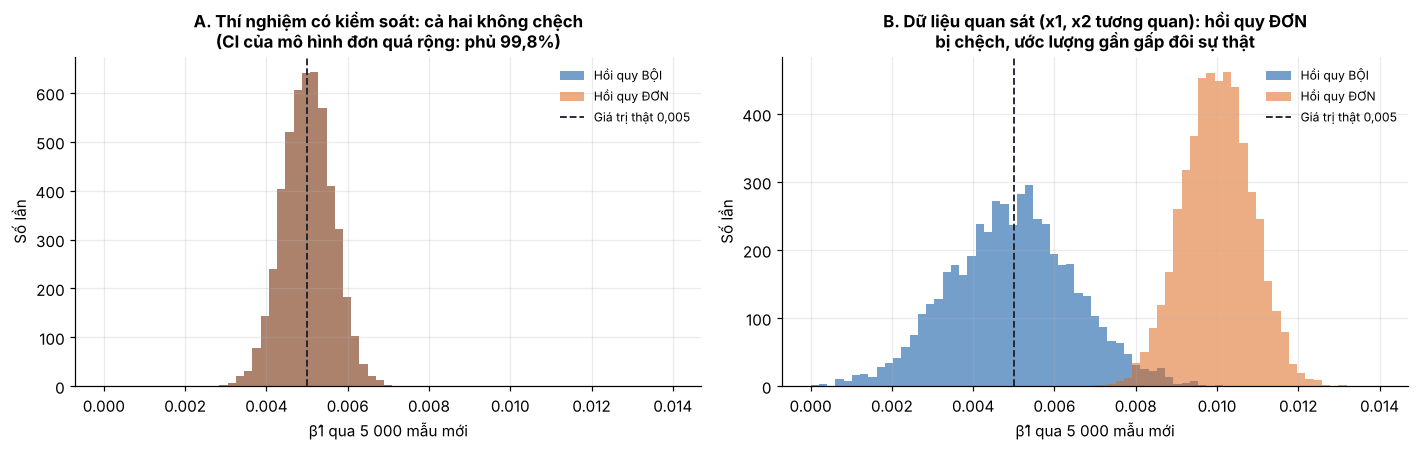

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
bins = np.linspace(0, 0.014, 70)
ax[0].hist(bA[1], bins=bins, alpha=.65, color=C1, label="Hồi quy BỘI"); ax[0].hist(bAs[1], bins=bins, alpha=.55, color=C2, label="Hồi quy ĐƠN")
ax[0].axvline(T["b1"], color=INK, ls="--", lw=1.2, label="Giá trị thật 0,005")
ax[0].set(title="A. Thí nghiệm có kiểm soát: cả hai không chệch\n(CI của mô hình đơn quá rộng: phủ 99,8%)", xlabel="β̂1 qua 5 000 mẫu mới", ylabel="Số lần"); ax[0].legend(fontsize=8)
ax[1].hist(bB_m[1], bins=bins, alpha=.65, color=C1, label="Hồi quy BỘI"); ax[1].hist(bB_s[1], bins=bins, alpha=.55, color=C2, label="Hồi quy ĐƠN")
ax[1].axvline(T["b1"], color=INK, ls="--", lw=1.2, label="Giá trị thật 0,005")
ax[1].set(title="B. Dữ liệu quan sát (x1, x2 tương quan): hồi quy ĐƠN\nbị chệch, ước lượng gần gấp đôi sự thật", xlabel="β̂1 qua 5 000 mẫu mới", ylabel="Số lần"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("fig09_montecarlo")

**Đọc kết quả (thông điệp cho giảng viên):**
1. **Kịch bản A:** cả hai mô hình đều **không chệch** (TB ≈ 0,005). Hồi quy **bội** có CI 95% phủ đúng ≈ 95% (95,3%) ⇒ quy trình ước lượng/kiểm định của nhóm **đáng tin**. Hồi quy **đơn** cũng đúng về giá trị nhưng CI **quá rộng** (phủ ≈ 99,8%) vì nó coi tác động của tải là nhiễu ⇒ kết luận *an toàn nhưng kém sắc*: với tác động nhỏ hơn, nó sẽ mất lực kiểm định.
2. **Kịch bản B:** mô hình đơn **chệch nặng** vì "ăn gian" cả tác động của tải ($\beta_1^{đơn}\approx\beta_1+\beta_2\cdot\frac{\text{Cov}(x_1,x_2)}{\text{Var}(x_1)}$) — và **CI 95% gần như không bao giờ chứa giá trị thật** (độ phủ ≈ 0%). Hồi quy bội vẫn không chệch và phủ ≈ 95%, nhưng phải trả "giá" là SD lớn hơn (≈ 0,0015 so với 0,0008) do $x_1,x_2$ tương quan cao — *đúng nhưng kém chắc* tốt hơn *chắc nhưng sai*.
3. **Bài học thực hành:** thiết kế thí nghiệm cân bằng bảo vệ ta khỏi thiên lệch biến bị bỏ sót; khi chỉ có dữ liệu quan sát, **phải đưa các biến liên quan vào mô hình** — đây cũng là lý do Mục 9 yêu cầu thu thập thêm biến.

---
# 11. Bảng tổng hợp đáp án

In [28]:
ci1 = m2.conf_int()
summary = pd.DataFrame([
 ["1", "Bảng thiết kế", "Giai thừa 5×3 = 15 tổ hợp × 4 lặp = 60 quan sát; trực giao (corr = 0, VIF = 1), có lặp, ngẫu hóa thứ tự"],
 ["2", "Hồi quy đơn (x1)", f"ŷ = {m1.params['Intercept']:.3f} + {m1.params['x1']:.5f}·x1 ; R² = {m1.rsquared:.3f} ; R²hc = {m1.rsquared_adj:.3f} ; s = {np.sqrt(m1.mse_resid):.2f} ms"],
 ["3", "Hồi quy bội (x1, x2)", f"ŷ = {m2.params['Intercept']:.3f} + {m2.params['x1']:.5f}·x1 + {m2.params['x2']:.4f}·x2 ; R² = {m2.rsquared:.3f} ; R²hc = {m2.rsquared_adj:.3f} ; s = {np.sqrt(m2.mse_resid):.2f} ms"],
 ["4", "Ý nghĩa hệ số", f"+100 byte ⇒ +{100*b1:.2f} ms ; +10 điểm % tải ⇒ +{10*b2:.2f} ms (mỗi hệ số khi giữ biến còn lại cố định)"],
 ["5", "Kiểm định & so sánh", f"p(β1) {fmt_p(m2.pvalues['x1'])}, p(β2) {fmt_p(m2.pvalues['x2'])} → cả hai có ý nghĩa; F từng phần = {F:.1f} (p {fmt_p(pF)}); R²hc {m1.rsquared_adj:.3f} → {m2.rsquared_adj:.3f}; SSE giảm {100*(1-m2.ssr/m1.ssr):.0f}%"],
 ["6", "Dự đoán (1000 byte, 60%)", f"ŷ = {y0:.2f} ms ; CI 95% (TB) [{ci_m[0]:.2f}; {ci_m[1]:.2f}] ; PI 95% (1 gói) [{pi_o[0]:.2f}; {pi_o[1]:.2f}]"],
 ["7", "Yếu tố chưa xét / giới hạn", "Biến bỏ sót (băng thông, hop, hàng đợi, mất gói…), phi tuyến khi tải→100%, tương tác, nhiễu không chuẩn/đuôi dài; chỉ dùng trong dải 200–1400 byte & 20–80%"],
 ["KL", "Biến cần thu thập", "Băng thông & mức sử dụng, số hop/RTT nền, độ dài hàng đợi, mất gói/truyền lại, loại lưu lượng, CPU máy chủ, loại liên kết, thời điểm, QoS, jitter/phân vị"],
], columns=["YC", "Nội dung", "Kết quả"])
pd.set_option("display.max_colwidth", 300); display(summary.set_index("YC"))
summary.to_csv("ket_qua_tong_hop.csv", index=False)
print("Đã lưu: data_de3_latency.csv, ket_qua_tong_hop.csv, thư mục figs/ (các biểu đồ dùng cho slide)")

,Nội dung,Kết quả
YC,,
1,Bảng thiết kế,"Giai thừa 5×3 = 15 tổ hợp × 4 lặp = 60 quan sát; trực giao (corr = 0, VIF = 1), có lặp, ngẫu hóa thứ tự"
2,Hồi quy đơn (x1),ŷ = 9.467 + 0.00547·x1 ; R² = 0.354 ; R²hc = 0.343 ; s = 3.19 ms
3,"Hồi quy bội (x1, x2)",ŷ = 4.821 + 0.00547·x1 + 0.0929·x2 ; R² = 0.695 ; R²hc = 0.684 ; s = 2.21 ms
4,Ý nghĩa hệ số,+100 byte ⇒ +0.55 ms ; +10 điểm % tải ⇒ +0.93 ms (mỗi hệ số khi giữ biến còn lại cố định)
5,Kiểm định & so sánh,"p(β1) <0.0001, p(β2) <0.0001 → cả hai có ý nghĩa; F từng phần = 63.7 (p <0.0001); R²hc 0.343 → 0.684; SSE giảm 53%"
6,"Dự đoán (1000 byte, 60%)",ŷ = 15.86 ms ; CI 95% (TB) [15.19; 16.53] ; PI 95% (1 gói) [11.39; 20.34]
7,Yếu tố chưa xét / giới hạn,"Biến bỏ sót (băng thông, hop, hàng đợi, mất gói…), phi tuyến khi tải→100%, tương tác, nhiễu không chuẩn/đuôi dài; chỉ dùng trong dải 200–1400 byte & 20–80%"
KL,Biến cần thu thập,"Băng thông & mức sử dụng, số hop/RTT nền, độ dài hàng đợi, mất gói/truyền lại, loại lưu lượng, CPU máy chủ, loại liên kết, thời điểm, QoS, jitter/phân vị"


Đã lưu: data_de3_latency.csv, ket_qua_tong_hop.csv, thư mục figs/ (các biểu đồ dùng cho slide)


---
### Tái lập kết quả
`SEED = 20261114` · dữ liệu gốc: `data_de3_latency.csv` · mã lệnh: notebook này · kết quả: `ket_qua_tong_hop.csv` và `figs/`. Chạy *Restart & Run All* sẽ cho đúng các số trên.